# Equipo 4 – Práctica 3.2 Asociación (Apriori y FP-Growth)
**Minería de Datos – Práctica 3.2 Asociación · Reglas de asociación sobre Transacciones de Ventas**

Análisis del comportamiento de ventas a partir de la **asociación de productos más significativos**, para crear promociones bajo dos requerimientos:

- **A. En general** (todo el catálogo).
- **B. En específico para Comidas Preparadas.**

Para cada requerimiento se siguen los 8 pasos de la práctica: caso de negocio, variables, soporte mínimo, antecedente y consecuente, impacto, evaluación con *confidence* y *lift*, comparación de Apriori vs FP-Growth y conclusiones de negocio.

### Guía de la práctica: dónde está cada paso
| Paso solicitado | Requerimiento A (en general) | Requerimiento B (Comidas Preparadas) |
|---|---|---|
| 1. Caso de negocio | A.1 | B.1 |
| 2. Variables consideradas | A.2 | B.2 |
| 3. Umbral mínimo de soporte | A.3 | B.3 (B-1 y B-2) |
| 4. Antecedente y consecuente | A.4a Apriori · A.4b FP-Growth | B.4 (Apriori y FP-Growth) |
| 5. Impacto de las variables | A.5 | B.5 |
| 6. Evaluación con Confidence y Lift | A.6 | B.6 |
| 7. Comparación de los 2 algoritmos | A.7 | B.7 |
| 8. Conclusiones de negocio | A.8 | B.8 |

Al final del notebook: comparación general de algoritmos y conclusiones finales.

## 0. Preparación

**Métricas que se usan en todo el notebook** (para una regla *A → B*, sobre el total de canastas):

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **Soporte** | P(A ∩ B) | Qué proporción de tickets contiene A y B juntos |
| **Confianza (confidence)** | P(B \| A) = soporte(A∪B) / soporte(A) | De los tickets con A, qué proporción también lleva B |
| **Lift** | confianza / P(B) | Cuántas veces más probable es B cuando hay A, respecto a su frecuencia normal. **>1** asociación positiva, **=1** independencia, **<1** se evitan |

La confianza sola engaña cuando B es un producto muy popular; por eso se exige también **lift > 1**.

In [1]:
# Silencia el DeprecationWarning de Colab ("datetime.utcnow() is deprecated"): lo emite jupyter_client
# cada vez que envía una salida a pantalla; no afecta los resultados. Aquí se reemplaza su función por la moderna.
import datetime
try:
    import jupyter_client.session as _jc
    _jc.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)
except Exception:
    pass

import time, os, subprocess, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
from IPython.display import display, Markdown

try:
    import mlxtend
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlxtend"])
    import mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 90)
print("mlxtend", mlxtend.__version__)

mlxtend 0.25.0


In [2]:
RUTA = "Transacciones_de_ventas Practica.csv"

raw = pd.read_csv(RUTA, encoding="latin-1")   # el archivo no está en UTF-8
print("Dimensiones originales:", raw.shape)

Dimensiones originales: (58903, 33)


### Limpieza mínima necesaria para este análisis
Se aplica solo lo que afecta a las canastas (el resto de la limpieza está documentada en la parte de agrupación):
- quitar espacios sobrantes (`ACEITES  Y MANTECAS` → `ACEITES Y MANTECAS`);
- reparar la codificación de `Descripcion` (`ESPAÃ\x91OL` → `ESPAÑOL`);
- completar el sector truncado `MNTQUILLAS Y MARGARI` y homologar `PASTA_ace` → `PASTA`;
- `Transaccion` como texto (es un identificador, no una cantidad).

In [3]:
df = raw.copy()
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip().str.replace(r"\s+", " ", regex=True)

def arregla(s):
    try:    return s.encode("latin-1").decode("utf-8")
    except Exception: return s

df["Descripcion"] = df["Descripcion"].map(arregla)
df["Descripcion"] = (df["Descripcion"].str.replace("CAMPOFRÃ�O", "CAMPOFRIO", regex=False)
                                      .str.replace("HERSHEYÂ´S", "HERSHEYS", regex=False))
df["Sector"] = df["Sector"].replace({"MNTQUILLAS Y MARGARI": "MANTEQUILLAS Y MARGARINAS"})
df["Linea"]  = df["Linea"].replace({"PASTA_ace": "PASTA"})
df["Transaccion"] = df["Transaccion"].astype(str)

N_TX = df["Transaccion"].nunique()
print(f"Líneas de detalle: {len(df):,} | Tickets (canastas): {N_TX:,} | Líneas de producto: {df['Linea'].nunique()} | Productos: {df['Producto'].nunique()}")

Líneas de detalle: 58,903 | Tickets (canastas): 11,344 | Líneas de producto: 60 | Productos: 479


### Funciones auxiliares
Se definen una sola vez y se reutilizan en A y B:
`canasta` (matriz ticket × ítem en presencia/ausencia), `reglas` (genera y formatea reglas), `correr` (ejecuta Apriori **y** FP-Growth y mide tiempos), `comparar`, `barrido` (prueba varios soportes), `impacto`, `participacion`, `dispersion` y `tabla`.

Para los pasos 6 y 7 se agregan, en la celda siguiente, `evaluar_algoritmos` (confidence y lift por algoritmo), `diferencia_metricas` (comprueba que ambos algoritmos devuelven las mismas métricas) y `frase_tiempos` (redacta la comparación de tiempos con lo medido).

In [4]:
fmt = lambda s: "{" + ", ".join(sorted(s)) + "}"

def canasta(d, col):
    # Matriz booleana: una fila por ticket, una columna por ítem (1 = el ticket lo contiene).
    return pd.crosstab(d["Transaccion"], d[col]).gt(0)

def reglas(fi, n_canastas, conf=0.5, lift_min=1.0):
    # Reglas A -> B con confianza >= conf y lift > lift_min.
    cols = ["antecedents", "consequents", "support", "confidence", "lift", "leverage", "conviction"]
    if not (fi["itemsets"].map(len) >= 2).any():
        return pd.DataFrame(columns=cols + ["Antecedente", "Consecuente", "n_ant", "n_cons"])
    try:
        r = association_rules(fi, num_itemsets=n_canastas, metric="confidence", min_threshold=conf)
    except TypeError:
        r = association_rules(fi, metric="confidence", min_threshold=conf)
    r = r[r["lift"] > lift_min][cols].copy()
    r["Antecedente"] = r["antecedents"].map(fmt)
    r["Consecuente"] = r["consequents"].map(fmt)
    r["n_ant"] = r["antecedents"].map(len)
    r["n_cons"] = r["consequents"].map(len)
    return r.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)

def correr(b, minsup, conf=0.5, reps=5):
    # Ejecuta Apriori y FP-Growth con el mismo soporte; repite para estabilizar el tiempo.
    out = {}
    for nombre, f in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        ts = []
        for _ in range(reps):
            t0 = time.perf_counter()
            fi = f(b, min_support=minsup, use_colnames=True)
            ts.append(time.perf_counter() - t0)
        out[nombre] = {"fi": fi, "reglas": reglas(fi, len(b), conf),
                       "t_media": float(np.mean(ts)), "t_min": float(np.min(ts))}
    return out

def comparar(out):
    # Tabla comparativa y verificación de que ambos algoritmos devuelven lo mismo.
    filas = []
    for n, o in out.items():
        fi = o["fi"]
        filas.append({"Algoritmo": n, "Itemsets frecuentes": len(fi),
                      "Itemsets de 2+ ítems": int((fi["itemsets"].map(len) >= 2).sum()),
                      "Reglas": len(o["reglas"]),
                      "Tiempo medio (s)": round(o["t_media"], 4), "Tiempo mínimo (s)": round(o["t_min"], 4)})
    a, f = out["Apriori"], out["FP-Growth"]
    sa = {frozenset(i): round(s, 8) for i, s in zip(a["fi"]["itemsets"], a["fi"]["support"])}
    sf = {frozenset(i): round(s, 8) for i, s in zip(f["fi"]["itemsets"], f["fi"]["support"])}
    ra = set(zip(a["reglas"]["antecedents"], a["reglas"]["consequents"]))
    rf = set(zip(f["reglas"]["antecedents"], f["reglas"]["consequents"]))
    print("¿Mismos itemsets con el mismo soporte?:", sa == sf)
    print("¿Mismas reglas?:", ra == rf)
    return pd.DataFrame(filas)

def barrido(b, soportes, conf=0.5):
    # Cuántos itemsets y reglas salen con cada soporte mínimo (para justificar el umbral).
    filas = []
    for s in soportes:
        fi = fpgrowth(b, min_support=s, use_colnames=True)
        r = reglas(fi, len(b), conf)
        filas.append({"Soporte mínimo": f"{s*100:.1f}%", "Tickets mínimos": int(np.ceil(s * len(b))),
                      "Ítems frecuentes": int((fi["itemsets"].map(len) == 1).sum()),
                      "Itemsets de 2+ ítems": int((fi["itemsets"].map(len) >= 2).sum()),
                      f"Reglas (conf≥{conf:.0%}, lift>1)": len(r)})
    return pd.DataFrame(filas)

def tabla(r, n=15, cols=("Antecedente", "Consecuente", "support", "confidence", "lift")):
    t = r[list(cols)].head(n).rename(columns={"support": "Soporte", "confidence": "Confianza", "lift": "Lift"})
    return t.round(3)

def impacto(r, b, imp_item, n=10):
    # Tickets e importe asociados a cada regla (antecedente + consecuente presentes a la vez).
    imp_item = imp_item.reindex(index=b.index, columns=b.columns).fillna(0)
    total = imp_item.values.sum()
    filas = []
    for _, x in r.head(n).iterrows():
        ant, con = list(x["antecedents"]), list(x["consequents"])
        m = b[ant + con].all(axis=1)
        filas.append({"Antecedente": x["Antecedente"], "Consecuente": x["Consecuente"],
                      "Tickets": int(m.sum()), "% de tickets": round(m.mean() * 100, 1),
                      "Importe de esos tickets ($)": round(imp_item.loc[m].values.sum()),
                      "% del importe": round(imp_item.loc[m].values.sum() / total * 100, 1),
                      "Importe del consecuente ($)": round(imp_item.loc[m, con].values.sum())})
    return pd.DataFrame(filas)

def participacion(r, n=15, titulo=""):
    # En cuántas reglas aparece cada ítem como antecedente o como consecuente.
    ant = pd.Series([i for s in r["antecedents"] for i in s]).value_counts().rename("Como antecedente")
    con = pd.Series([i for s in r["consequents"] for i in s]).value_counts().rename("Como consecuente")
    t = pd.concat([ant, con], axis=1).fillna(0)
    t["total"] = t.sum(axis=1)
    t = t.sort_values("total", ascending=False).head(n).drop(columns="total")
    t.sort_values("Como antecedente").plot(kind="barh", stacked=True, figsize=(8, 0.38 * len(t) + 1.5),
                                           color=["#2f6fa5", "#e07b39"])
    plt.title(titulo or "Participación de cada ítem en las reglas"); plt.xlabel("Número de reglas"); plt.ylabel("")
    plt.tight_layout(); plt.show()
    return t

def dispersion(r, titulo):
    plt.figure(figsize=(8, 5.5))
    sc = plt.scatter(r["support"], r["confidence"], c=r["lift"], cmap="viridis", s=28, alpha=.75)
    plt.colorbar(sc, label="Lift")
    plt.xlabel("Soporte"); plt.ylabel("Confianza"); plt.title(titulo)
    plt.tight_layout(); plt.show()

resumen_tiempos = []   # se llena en cada comparación y se resume al final

In [5]:
# Funciones adicionales para los pasos 6 (evaluación por algoritmo) y 7 (comparación de algoritmos)
def evaluar_algoritmos(out, nombre):
    # Confidence y lift de las reglas que produce cada algoritmo.
    filas = []
    for alg, o in out.items():
        r = o["reglas"]
        filas.append({"Conjunto": nombre, "Algoritmo": alg, "Reglas": len(r),
                      "Confianza media": r["confidence"].mean(), "Confianza mediana": r["confidence"].median(),
                      "Lift medio": r["lift"].mean(), "Lift mediano": r["lift"].median(), "Lift máximo": r["lift"].max(),
                      "Reglas con lift ≥ 1.5": int((r["lift"] >= 1.5).sum()), "Reglas con lift ≥ 2": int((r["lift"] >= 2).sum())})
    return pd.DataFrame(filas).round(3)

def diferencia_metricas(out):
    # ¿Mismas reglas en ambos algoritmos? y mayor diferencia absoluta en soporte, confianza y lift.
    a, f = out["Apriori"]["reglas"], out["FP-Growth"]["reglas"]
    m = a.merge(f, on=["Antecedente", "Consecuente"], suffixes=("_a", "_f"))
    dif = 0.0 if m.empty else max(float((m[c + "_a"] - m[c + "_f"]).abs().max()) for c in ["support", "confidence", "lift"])
    return len(m) == len(a) == len(f), dif

def frase_tiempos(out):
    # Compara los tiempos medios medidos en esta corrida.
    ta, tf = out["Apriori"]["t_media"], out["FP-Growth"]["t_media"]
    gana, pierde = ("Apriori", "FP-Growth") if ta <= tf else ("FP-Growth", "Apriori")
    return f"Apriori {ta:.3f} s y FP-Growth {tf:.3f} s: {gana} fue {max(ta, tf) / min(ta, tf):.1f} veces más rápido que {pierde}."

---
# REQUERIMIENTO A. En general (todo el catálogo)

## A.1 Caso de negocio
La empresa vende alimentos (carnes frías, quesos, comidas preparadas, yoghurt, etc.) a empleados de empresas corporativas. Cada ticket mezcla en promedio más de 4 líneas de producto distintas, pero hoy las promociones se definen producto por producto, sin saber **qué se compra junto**.

**Objetivo:** descubrir qué líneas de producto se asocian de forma significativa para diseñar **promociones cruzadas y combos** (por ejemplo: *si el cliente lleva A, ofrecer descuento en B*), ubicar productos juntos y decidir qué líneas conviene empujar.

**Técnica:** reglas de asociación con **Apriori** y **FP-Growth** sobre las canastas de compra (tickets).

## A.2 Variables consideradas
| Variable | Papel en el análisis | Justificación |
|---|---|---|
| `Transaccion` | **Identificador de canasta** | Un ticket es el conjunto de productos comprados juntos |
| `Linea` | **Ítem** | 60 categorías; nivel de detalle suficiente para que una promoción sea accionable |
| `Importe` | Medida de **impacto económico** | No entra a los algoritmos; se usa para cuantificar cuánto dinero hay detrás de cada regla |
| `Sector` | Filtro (se usa en el requerimiento B) | Permite aislar Comidas Preparadas |

Se descartan las variables demográficas del cliente (edad, sexo, etc.) porque las reglas de asociación trabajan con *qué* se compra en conjunto, no con *quién* compra. También se descarta `Cantidad`: lo relevante es si el producto está o no en el ticket.

**¿Qué nivel de producto usar como ítem?** Se compara la jerarquía de producto:

In [6]:
filas = []
for nivel in ["Producto", "Sublinea", "Linea", "Tipo", "Sector"]:
    g = df.groupby("Transaccion")[nivel].nunique()
    filas.append({"Nivel": nivel, "Ítems distintos": df[nivel].nunique(),
                  "Tickets con 2+ ítems": f"{(g >= 2).mean()*100:.1f}%", "Ítems por ticket (media)": round(g.mean(), 2)})
display(pd.DataFrame(filas))

,Nivel,Ítems distintos,Tickets con 2+ ítems,Ítems por ticket (media)
0,Producto,479,79.6%,5.19
1,Sublinea,96,77.6%,4.66
2,Linea,60,76.9%,4.27
3,Tipo,43,74.8%,3.47
4,Sector,12,72.3%,2.72


**Decisión:** se usa `Linea` (60 ítems). `Producto` (479 ítems) deja una matriz muy dispersa donde casi nada alcanza un soporte razonable; `Sector` (12 ítems) es tan general que las promociones no serían accionables. `Linea` conserva 76.9% de tickets con 2 o más ítems y reglas legibles.

Matriz de canastas: (11344, 60) (tickets × líneas)


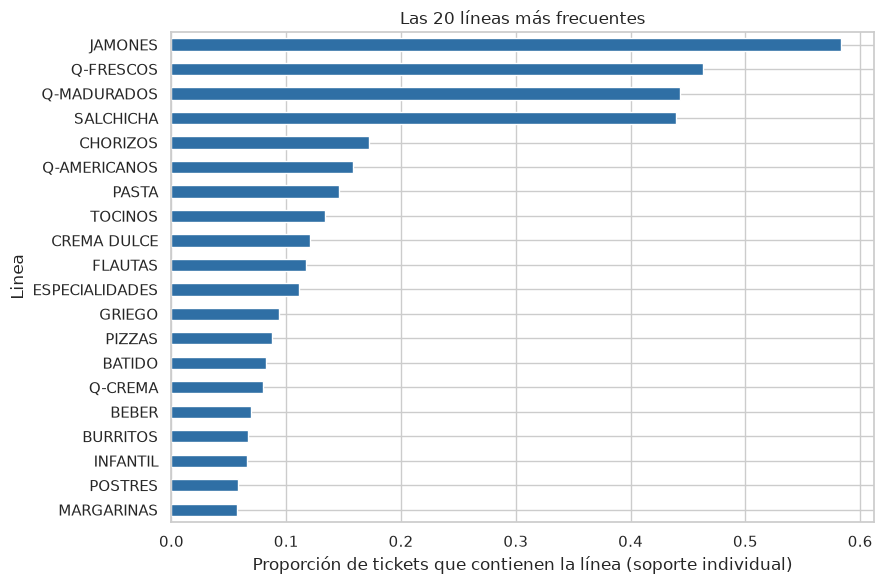

In [7]:
b_A = canasta(df, "Linea")
imp_A = df.pivot_table(index="Transaccion", columns="Linea", values="Importe", aggfunc="sum", fill_value=0)
print("Matriz de canastas:", b_A.shape, "(tickets × líneas)")

frec = b_A.mean().sort_values(ascending=False)
plt.figure(figsize=(9, 6))
frec.head(20).sort_values().plot(kind="barh", color="#2f6fa5")
plt.xlabel("Proporción de tickets que contienen la línea (soporte individual)")
plt.title("Las 20 líneas más frecuentes"); plt.tight_layout(); plt.show()

## A.3 Umbral mínimo de soporte
El soporte mínimo es un compromiso: si es muy alto solo aparecen combinaciones obvias; si es muy bajo se genera una cantidad inmanejable de reglas poco respaldadas. Se prueban varios valores con una confianza mínima de 50% y lift > 1:

In [8]:
bar_A = barrido(b_A, [0.10, 0.05, 0.03, 0.02, 0.01], conf=0.5)
display(bar_A)

,Soporte mínimo,Tickets mínimos,Ítems frecuentes,Itemsets de 2+ ítems,"Reglas (conf≥50%, lift>1)"
0,10.0%,1135,11,20,40
1,5.0%,568,21,96,192
2,3.0%,341,28,245,551
3,2.0%,227,35,443,1096
4,1.0%,114,46,1295,3582


**Soporte mínimo elegido: 3%** (≈ 341 de 11,344 tickets). Razones:
- Cada regla está respaldada por cientos de tickets, no por casualidades.
- Con 5% se pierden 7 líneas de menor rotación (Res, Light, Placer, Diversos, Enlatados, Chocolates y Listos para consumo); con 1% el número de reglas se dispara a más de 3,500, imposible de convertir en promociones.
- **Confianza mínima: 50%** y **lift > 1** para quedarse solo con asociaciones positivas.

In [9]:
SOP_A, CONF_A = 0.03, 0.50
out_A = correr(b_A, SOP_A, CONF_A)
print(f"Soporte mínimo = {SOP_A:.0%} (≈ {int(np.ceil(SOP_A*len(b_A)))} tickets) | Confianza mínima = {CONF_A:.0%} | Lift > 1")

Soporte mínimo = 3% (≈ 341 tickets) | Confianza mínima = 50% | Lift > 1


## A.4 Algoritmos, antecedente y consecuente
En cada regla **A → B**, el **antecedente** (A) es lo que ya lleva el cliente y el **consecuente** (B) es lo que probablemente también llevará: es el producto candidato a promoción.

### A.4a Apriori

In [10]:
fi = out_A["Apriori"]["fi"]; r_ap = out_A["Apriori"]["reglas"]
fi2 = fi.assign(Itemset=fi["itemsets"].map(fmt), Ítems=fi["itemsets"].map(len))
print("Itemsets frecuentes más grandes (por soporte) con 3+ ítems:")
display(fi2[fi2["Ítems"] >= 3].sort_values("support", ascending=False)[["Itemset", "support"]].head(8).round(3))
print(f"\nReglas encontradas por Apriori: {len(r_ap)}")
print("Top 15 por lift:")
display(tabla(r_ap, 15))

Itemsets frecuentes más grandes (por soporte) con 3+ ítems:


,Itemset,support
191,"{JAMONES, Q-FRESCOS, SALCHICHA}",0.217
190,"{JAMONES, Q-FRESCOS, Q-MADURADOS}",0.191
193,"{JAMONES, Q-MADURADOS, SALCHICHA}",0.179
212,"{Q-FRESCOS, Q-MADURADOS, SALCHICHA}",0.151
261,"{JAMONES, Q-FRESCOS, Q-MADURADOS, SALCHICHA}",0.127
133,"{CHORIZOS, JAMONES, SALCHICHA}",0.105
131,"{CHORIZOS, JAMONES, Q-FRESCOS}",0.100
185,"{JAMONES, Q-AMERICANOS, SALCHICHA}",0.093



Reglas encontradas por Apriori: 551
Top 15 por lift:


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{CHORIZOS, JAMONES, Q-FRESCOS, Q-MADURADOS}",{Q-AMERICANOS},0.030,0.511,3.233
1,"{JAMONES, Q-AMERICANOS, Q-FRESCOS, SALCHICHA}",{CHORIZOS},0.037,0.541,3.153
2,"{CREMA DULCE, Q-FRESCOS, SALCHICHA}",{CHORIZOS},0.034,0.541,3.150
3,"{CREMA DULCE, JAMONES, SALCHICHA}",{CHORIZOS},0.036,0.529,3.078
4,"{JAMONES, Q-AMERICANOS, Q-FRESCOS, Q-MADURADOS}",{CHORIZOS},0.030,0.512,2.981
5,"{Q-AMERICANOS, Q-FRESCOS, SALCHICHA}",{CHORIZOS},0.040,0.512,2.980
6,"{CREMA DULCE, SALCHICHA}",{CHORIZOS},0.041,0.507,2.950
7,"{CREMA DULCE, JAMONES, Q-FRESCOS}",{CHORIZOS},0.036,0.504,2.937
8,"{CHORIZOS, Q-AMERICANOS}","{JAMONES, Q-FRESCOS, SALCHICHA}",0.037,0.595,2.740
9,"{CHORIZOS, PASTA}","{Q-FRESCOS, SALCHICHA}",0.032,0.680,2.585


### A.4b FP-Growth

In [11]:
r_fp = out_A["FP-Growth"]["reglas"]
print(f"Reglas encontradas por FP-Growth: {len(r_fp)}")
print("Top 10 por lift:")
display(tabla(r_fp, 10))

Reglas encontradas por FP-Growth: 551
Top 10 por lift:


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{CHORIZOS, JAMONES, Q-FRESCOS, Q-MADURADOS}",{Q-AMERICANOS},0.030,0.511,3.233
1,"{JAMONES, Q-AMERICANOS, Q-FRESCOS, SALCHICHA}",{CHORIZOS},0.037,0.541,3.153
2,"{CREMA DULCE, Q-FRESCOS, SALCHICHA}",{CHORIZOS},0.034,0.541,3.150
3,"{CREMA DULCE, JAMONES, SALCHICHA}",{CHORIZOS},0.036,0.529,3.078
4,"{JAMONES, Q-AMERICANOS, Q-FRESCOS, Q-MADURADOS}",{CHORIZOS},0.030,0.512,2.981
5,"{Q-AMERICANOS, Q-FRESCOS, SALCHICHA}",{CHORIZOS},0.040,0.512,2.980
6,"{CREMA DULCE, SALCHICHA}",{CHORIZOS},0.041,0.507,2.950
7,"{CREMA DULCE, JAMONES, Q-FRESCOS}",{CHORIZOS},0.036,0.504,2.937
8,"{CHORIZOS, Q-AMERICANOS}","{JAMONES, Q-FRESCOS, SALCHICHA}",0.037,0.595,2.740
9,"{CHORIZOS, PASTA}","{Q-FRESCOS, SALCHICHA}",0.032,0.680,2.585


Las reglas más largas (3 o 4 ítems en el antecedente) tienen lift alto pero son difíciles de usar en una promoción. La vista más **accionable** son las reglas simples *un producto → un producto*:

Reglas simples (1 → 1): 76 de 551


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,{CHORIZOS},{SALCHICHA},0.123,0.714,1.626
1,{MARGARINAS},{SALCHICHA},0.040,0.710,1.617
2,{INFANTIL},{SALCHICHA},0.045,0.687,1.565
3,{Q-AMERICANOS},{SALCHICHA},0.108,0.683,1.556
4,{CREMA DULCE},{Q-FRESCOS},0.087,0.719,1.552
5,{TOCINOS},{SALCHICHA},0.091,0.677,1.541
6,{CREMA DULCE},{SALCHICHA},0.081,0.671,1.527
7,{PASTA},{SALCHICHA},0.097,0.666,1.516
8,{LIGHT},{Q-FRESCOS},0.033,0.698,1.507
9,{BATIDO},{SALCHICHA},0.054,0.651,1.483


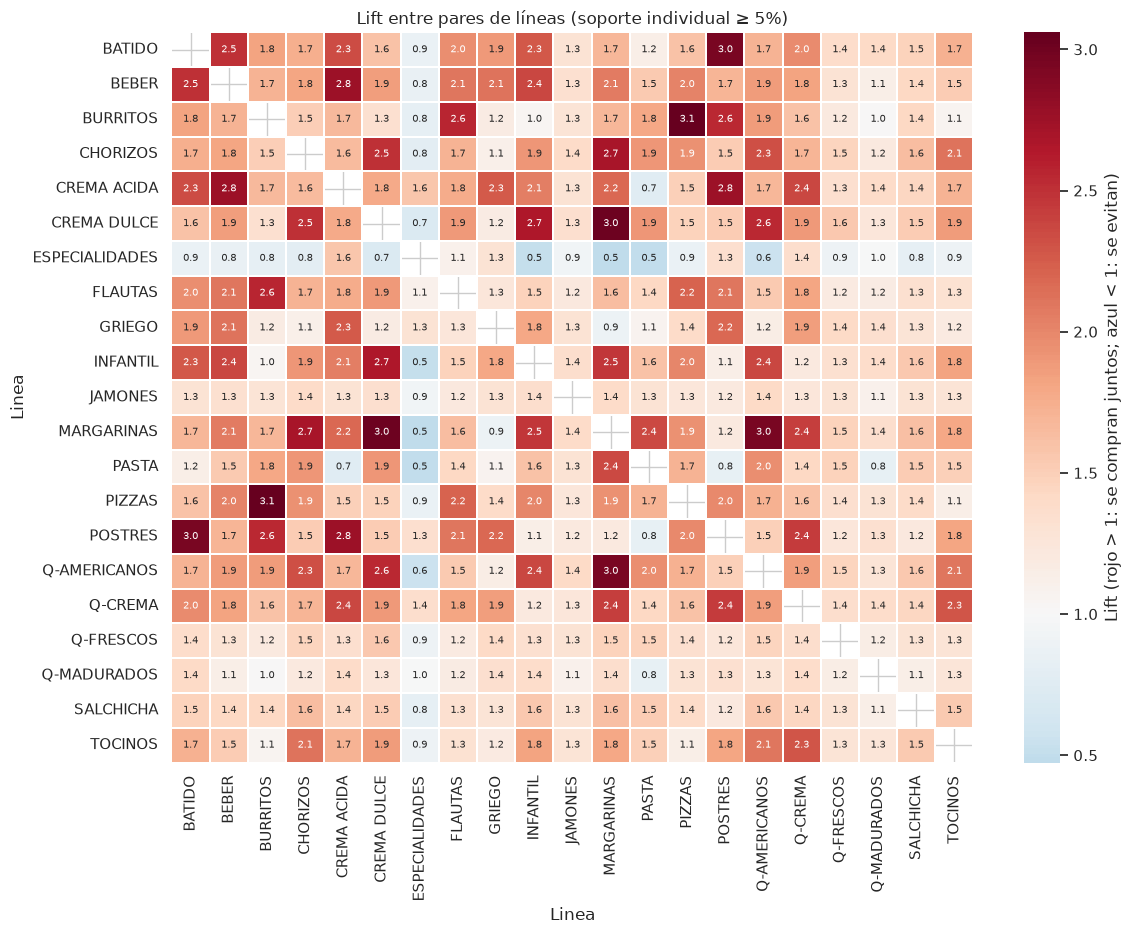

In [12]:
r_A1 = r_ap[(r_ap["n_ant"] == 1) & (r_ap["n_cons"] == 1)].reset_index(drop=True)
print(f"Reglas simples (1 → 1): {len(r_A1)} de {len(r_ap)}")
display(tabla(r_A1, 15))

# Mapa de lift entre las líneas más frecuentes
cols = b_A.columns[b_A.mean() >= 0.05]
X = b_A[cols].astype(int)
co = (X.T @ X) / len(X); p = X.mean()
lift_m = pd.DataFrame(co.values / np.outer(p.values, p.values), index=cols, columns=cols)
plt.figure(figsize=(12, 9.5))
sns.heatmap(lift_m, mask=np.eye(len(cols), dtype=bool), cmap="RdBu_r", center=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=.3, cbar_kws={"label": "Lift (rojo > 1: se compran juntos; azul < 1: se evitan)"})
plt.title("Lift entre pares de líneas (soporte individual ≥ 5%)"); plt.tight_layout(); plt.show()

**Cómo leer el mapa:** cada celda es el lift entre dos líneas (simétrico). Los pares más rojos (hasta 3.1, por ejemplo Burritos–Pizzas o Margarinas–Crema dulce) son los que más se compran juntos respecto a lo esperado. No todos llegan a ser reglas, porque además del lift se exige confianza ≥ 50% y soporte ≥ 3%. **ESPECIALIDADES**, la línea que más pesa en importe (19.6%), tiene lift menor a 1 con la mayoría de las demás líneas: tiende a comprarse aparte del resto.

## A.5 Impacto de las variables seleccionadas
El impacto se mide de dos formas: **(1)** cuánto dinero y cuántos tickets hay detrás de cada regla y **(2)** qué líneas participan más en las reglas (cuáles son las que "jalan" al resto).

In [13]:
print("Impacto económico de las 10 reglas con mayor soporte (1 → 1):")
r_A1_sup = r_A1.sort_values("support", ascending=False).reset_index(drop=True)
display(impacto(r_A1_sup, b_A, imp_A, 10))

Impacto económico de las 10 reglas con mayor soporte (1 → 1):


,Antecedente,Consecuente,Tickets,% de tickets,Importe de esos tickets ($),% del importe,Importe del consecuente ($)
0,{Q-FRESCOS},{JAMONES},3962,34.9,1201915,32.2,249991
1,{JAMONES},{Q-FRESCOS},3962,34.9,1201915,32.2,192552
2,{JAMONES},{SALCHICHA},3799,33.5,1187778,31.8,180566
3,{SALCHICHA},{JAMONES},3799,33.5,1187778,31.8,244602
4,{Q-MADURADOS},{JAMONES},3247,28.6,1084132,29.1,216247
5,{SALCHICHA},{Q-FRESCOS},2985,26.3,968449,26.0,144864
6,{Q-FRESCOS},{SALCHICHA},2985,26.3,968449,26.0,142364
7,{Q-FRESCOS},{Q-MADURADOS},2692,23.7,914241,24.5,171807
8,{Q-MADURADOS},{Q-FRESCOS},2692,23.7,914241,24.5,130341
9,{SALCHICHA},{Q-MADURADOS},2523,22.2,873683,23.4,161922


Impacto económico de las 10 reglas con mayor lift:


,Antecedente,Consecuente,Tickets,% de tickets,Importe de esos tickets ($),% del importe,Importe del consecuente ($)
0,"{CHORIZOS, JAMONES, Q-FRESCOS, Q-MADURADOS}",{Q-AMERICANOS},342,3.0,155401,4.2,8806
1,"{JAMONES, Q-AMERICANOS, Q-FRESCOS, SALCHICHA}",{CHORIZOS},425,3.7,178552,4.8,8973
2,"{CREMA DULCE, Q-FRESCOS, SALCHICHA}",{CHORIZOS},383,3.4,144126,3.9,8148
3,"{CREMA DULCE, JAMONES, SALCHICHA}",{CHORIZOS},407,3.6,159576,4.3,8574
4,"{JAMONES, Q-AMERICANOS, Q-FRESCOS, Q-MADURADOS}",{CHORIZOS},342,3.0,155401,4.2,7342
5,"{Q-AMERICANOS, Q-FRESCOS, SALCHICHA}",{CHORIZOS},455,4.0,188688,5.1,9615
6,"{CREMA DULCE, SALCHICHA}",{CHORIZOS},466,4.1,173757,4.7,9694
7,"{CREMA DULCE, JAMONES, Q-FRESCOS}",{CHORIZOS},414,3.6,158455,4.2,8817
8,"{CHORIZOS, Q-AMERICANOS}","{JAMONES, Q-FRESCOS, SALCHICHA}",425,3.7,178552,4.8,71799
9,"{CHORIZOS, PASTA}","{Q-FRESCOS, SALCHICHA}",368,3.2,142318,3.8,33538


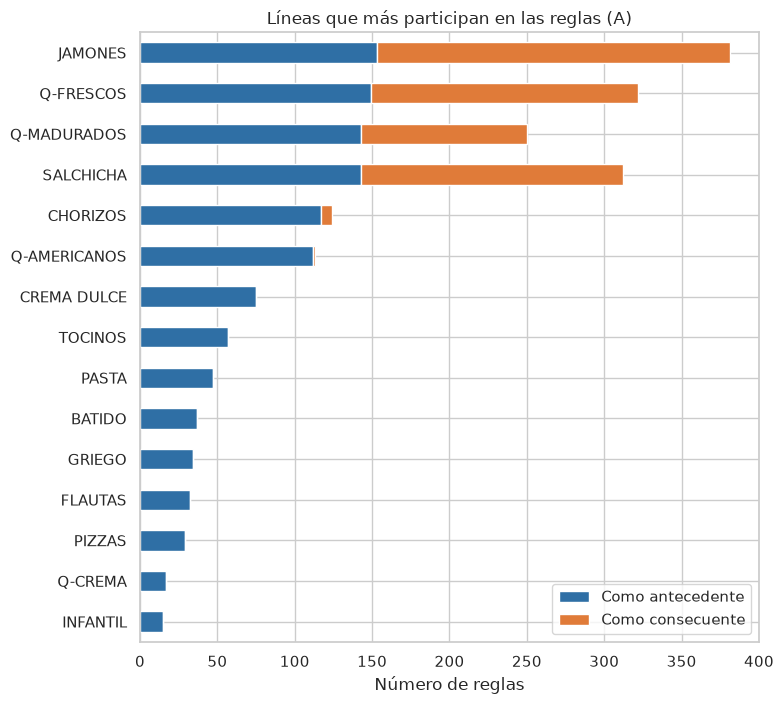


% del importe total por línea (top 8):
Linea
ESPECIALIDADES    19.6
Q-MADURADOS       19.2
JAMONES           11.9
Q-FRESCOS          7.4
SALCHICHA          6.6
NAVIDEÑOS          6.2
PASTA              2.4
FLAUTAS            2.0


In [14]:
print("Impacto económico de las 10 reglas con mayor lift:")
display(impacto(r_ap, b_A, imp_A, 10))

part_A = participacion(r_ap, 15, "Líneas que más participan en las reglas (A)")

imp_linea = (imp_A.sum() / imp_A.values.sum() * 100).sort_values(ascending=False)
print("\n% del importe total por línea (top 8):")
print(imp_linea.head(8).round(1).to_string())

**Lectura del impacto (A).**

- **Por dinero, mandan las reglas del núcleo.** Q-Frescos ↔ Jamones aparece en 3,962 tickets (34.9%) que concentran el 32.2% del importe total (≈ \$1.20 millones); Jamones ↔ Salchicha, en 3,799 tickets (33.5% de los tickets y 31.8% del importe); Q-Madurados → Jamones, en 3,247 (28.6% y 29.1%). Son las asociaciones con más dinero detrás, pero con lift bajo (ver A.6).
- **Las reglas de lift alto tocan menos tickets, pero de canastas grandes.** Las 8 reglas de mayor lift cubren entre 3.0% y 4.1% de los tickets y entre 3.9% y 5.1% del importe total; esos tickets suman entre \$144 mil y \$189 mil por regla. En las 7 que terminan en Chorizos, ese consecuente aporta entre \$7 mil y \$10 mil, alrededor de 5% del importe de esos tickets: el valor de la promoción está en completar el combo, no en el producto promovido por sí solo.
- **Importe por línea frente a participación en reglas.** Especialidades (19.6% del importe) y Q-Madurados (19.2%) son las líneas que más pesan en dinero; Jamones (11.9%), Q-Frescos (7.4%) y Salchicha (6.6%) completan el núcleo que domina las reglas de mayor soporte. Navideños pesa 6.2% del importe pero no participa en ninguna regla porque su soporte (2.7% de los tickets) queda bajo el umbral de 3% (ver A.8). La gráfica de participación muestra qué líneas actúan como antecedente y cuáles como consecuente.

## A.6 Evaluación del modelo: Confidence y Lift

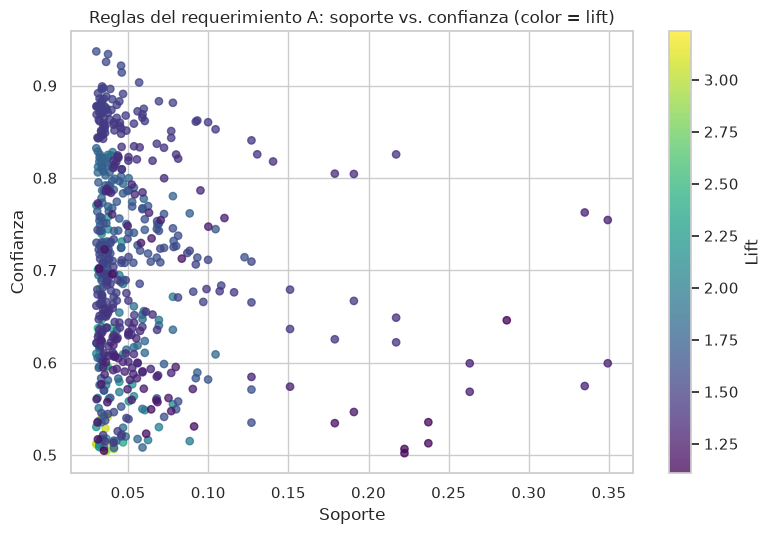

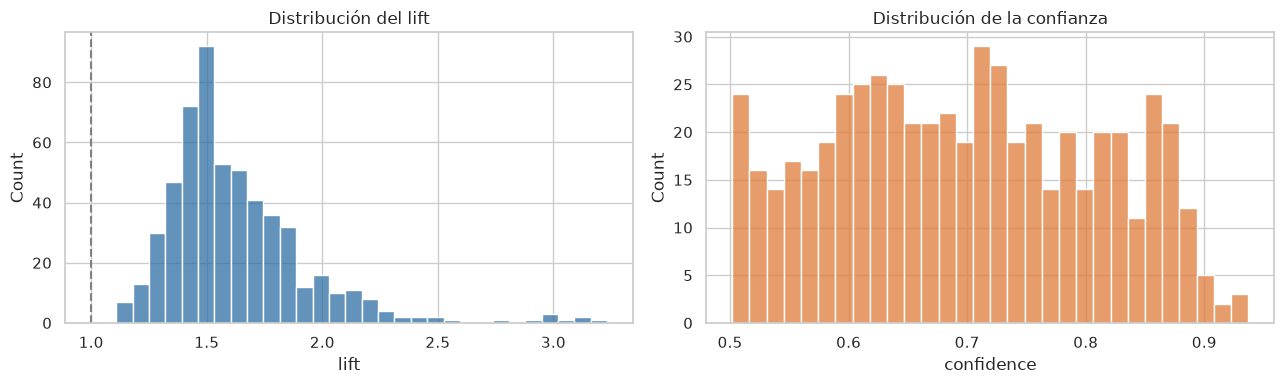

,Métrica,Mínimo,Mediana,Máximo
0,Confianza,0.502,0.696,0.937
1,Lift,1.108,1.546,3.233
2,Soporte,0.030,0.041,0.349


Reglas con lift ≥ 2: 55 de 551
Reglas con lift ≥ 1.5: 334 de 551


In [15]:
dispersion(r_ap, "Reglas del requerimiento A: soporte vs. confianza (color = lift)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(r_ap["lift"], bins=30, ax=ax[0], color="#2f6fa5"); ax[0].axvline(1, ls="--", c="gray"); ax[0].set_title("Distribución del lift")
sns.histplot(r_ap["confidence"], bins=30, ax=ax[1], color="#e07b39"); ax[1].set_title("Distribución de la confianza")
plt.tight_layout(); plt.show()

ev = pd.DataFrame({"Métrica": ["Confianza", "Lift", "Soporte"],
                   "Mínimo": [r_ap.confidence.min(), r_ap.lift.min(), r_ap.support.min()],
                   "Mediana": [r_ap.confidence.median(), r_ap.lift.median(), r_ap.support.median()],
                   "Máximo": [r_ap.confidence.max(), r_ap.lift.max(), r_ap.support.max()]}).round(3)
display(ev)
print("Reglas con lift ≥ 2:", int((r_ap.lift >= 2).sum()), "de", len(r_ap))
print("Reglas con lift ≥ 1.5:", int((r_ap.lift >= 1.5).sum()), "de", len(r_ap))

In [16]:
# Evaluación por algoritmo: confidence y lift de las reglas de Apriori y de FP-Growth
display(evaluar_algoritmos(out_A, "A"))
ok, dif = diferencia_metricas(out_A)
print(f"¿Mismas reglas en ambos algoritmos? {ok} | mayor diferencia en soporte/confianza/lift: {dif:.1e}")

,Conjunto,Algoritmo,Reglas,Confianza media,Confianza mediana,Lift medio,Lift mediano,Lift máximo,Reglas con lift ≥ 1.5,Reglas con lift ≥ 2
0,A,Apriori,551,0.697,0.696,1.627,1.546,3.233,334,55
1,A,FP-Growth,551,0.697,0.696,1.627,1.546,3.233,334,55


¿Mismas reglas en ambos algoritmos? True | mayor diferencia en soporte/confianza/lift: 0.0e+00


**Lectura de Confidence y Lift (A).** Las 551 reglas tienen confianza entre 50.2% y 93.7% (mediana 69.6%) y lift entre 1.11 y 3.23 (mediana 1.55); 334 tienen lift ≥ 1.5 y 55 tienen lift ≥ 2. Como el filtro exige lift > 1, todas son asociaciones positivas, pero la mayoría son moderadas.

- **Confianza alta no significa buena promoción.** Q-Frescos → Jamones tiene 75.4% de confianza pero lift de solo 1.29: Jamones está en 58.3% de todos los tickets, así que esa confianza refleja popularidad. En cambio, {Crema dulce, Salchicha} → Chorizos tiene confianza de 50.7% y lift de 2.95: quien lleva esos dos productos compra Chorizos casi 3 veces más seguido que el cliente promedio (17.2% de los tickets).
- **Criterio para elegir reglas de promoción:** lift ≥ 1.5, soporte ≥ 3% (≈ 341 tickets) y, de preferencia, antecedentes de 1 o 2 productos para que sean fáciles de operar.
- **Evaluación por algoritmo:** la tabla anterior muestra que Apriori y FP-Growth generan las mismas reglas con las mismas métricas; la calidad de las reglas (confidence y lift) no depende del algoritmo.

## A.7 Comparación de resultados de Apriori y FP-Growth

In [17]:
cmp_A = comparar(out_A)
display(cmp_A)
resumen_tiempos.append({"Experimento": "A (Linea, 3%)", "Apriori (s)": out_A["Apriori"]["t_media"], "FP-Growth (s)": out_A["FP-Growth"]["t_media"], "Reglas": len(r_ap)})

¿Mismos itemsets con el mismo soporte?: True
¿Mismas reglas?: True


,Algoritmo,Itemsets frecuentes,Itemsets de 2+ ítems,Reglas,Tiempo medio (s),Tiempo mínimo (s)
0,Apriori,273,245,551,0.0366,0.0300
1,FP-Growth,273,245,551,0.1086,0.0905


Ambos algoritmos deben producir **exactamente los mismos itemsets y las mismas reglas** (la verificación de arriba lo confirma): son dos formas de encontrar lo mismo. Apriori genera candidatos nivel por nivel y relee los datos; FP-Growth comprime las canastas en un árbol y no genera candidatos. Lo que puede cambiar es **el tiempo y la memoria**, y la diferencia depende de la escala, de cómo implementa cada algoritmo la librería y de su versión. Para ver cómo se comporta cada uno al crecer el problema, se repite el experimento a nivel `Producto` (479 ítems) bajando el soporte:

,Soporte,Itemsets,Apriori (s),FP-Growth (s),Apriori / FP-Growth
0,0.050,20,0.029,0.071,0.4
1,0.030,44,0.106,0.100,1.1
2,0.020,75,0.352,0.159,2.2
3,0.010,224,1.431,0.199,7.2
4,0.005,703,3.147,0.291,10.8


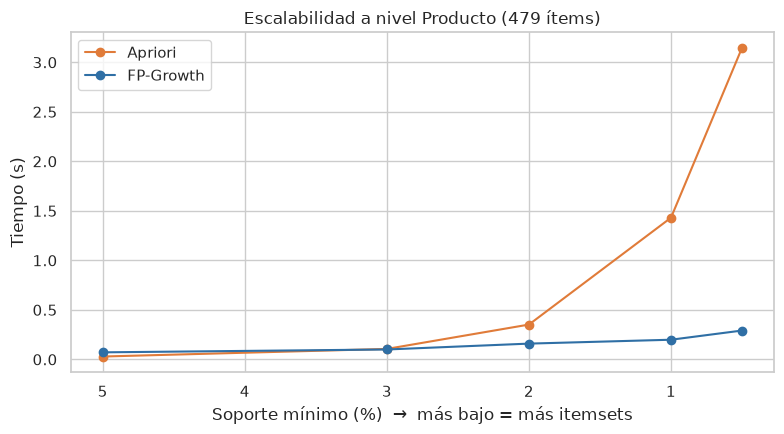

In [18]:
b_P = canasta(df, "Producto")
filas = []
for s in [0.05, 0.03, 0.02, 0.01, 0.005]:
    ta, tf = [], []
    for _ in range(3):
        t0 = time.perf_counter(); fa = apriori(b_P, min_support=s, use_colnames=True); ta.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); ff = fpgrowth(b_P, min_support=s, use_colnames=True); tf.append(time.perf_counter() - t0)
    filas.append({"Soporte": s, "Itemsets": len(fa), "Apriori (s)": np.mean(ta), "FP-Growth (s)": np.mean(tf)})
esc = pd.DataFrame(filas)
esc["Apriori / FP-Growth"] = (esc["Apriori (s)"] / esc["FP-Growth (s)"]).round(1)
display(esc.round(3))

plt.figure(figsize=(8, 4.5))
plt.plot(esc["Soporte"] * 100, esc["Apriori (s)"], "o-", label="Apriori", color="#e07b39")
plt.plot(esc["Soporte"] * 100, esc["FP-Growth (s)"], "o-", label="FP-Growth", color="#2f6fa5")
plt.gca().invert_xaxis(); plt.xlabel("Soporte mínimo (%)  →  más bajo = más itemsets"); plt.ylabel("Tiempo (s)")
plt.title("Escalabilidad a nivel Producto (479 ítems)"); plt.legend(); plt.tight_layout(); plt.show()

In [19]:
# Comentario comparativo (A.7): se redacta con los tiempos medidos en esta corrida
n_it, n_re = len(out_A["Apriori"]["fi"]), len(out_A["Apriori"]["reglas"])
ok, dif = diferencia_metricas(out_A)
razon = esc["FP-Growth (s)"] / esc["Apriori (s)"]
fp_gana = esc[esc["FP-Growth (s)"] < esc["Apriori (s)"]]
if fp_gana.empty:
    escala = "FP-Growth **no superó** a Apriori en ninguno de los soportes probados"
else:
    escala = "FP-Growth superó a Apriori con soporte de " + ", ".join(f"{s:.1%}" for s in fp_gana["Soporte"])

display(Markdown(f"""**Comentario de resultados comparativos (Requerimiento A)**

1. **Mismos resultados.** Con soporte {SOP_A:.0%}, ambos algoritmos encontraron {n_it} itemsets frecuentes y {n_re} reglas, con el mismo antecedente, consecuente, soporte, confianza y lift (diferencia máxima: {dif:.1e}; mismas reglas: {ok}). Para el negocio da igual cuál se use: las promociones que se derivan son las mismas.
2. **Tiempo con 60 líneas (soporte {SOP_A:.0%}).** {frase_tiempos(out_A)}
3. **Escalabilidad con 479 productos (soporte de 5% a 0.5%).** FP-Growth tardó entre {razon.min():.1f} y {razon.max():.1f} veces el tiempo de Apriori; {escala}.
4. **Interpretación.** La ventaja teórica de FP-Growth (evitar la generación de candidatos y leer la base solo dos veces) pesa más cuando hay muchos ítems frecuentes o itemsets largos. Aquí las canastas son cortas (≈ 4 líneas por ticket) y el tiempo observado depende también de cómo implementa cada algoritmo la librería (`mlxtend` {mlxtend.__version__}), no solo de su complejidad teórica. Por eso la comparación se basa en los tiempos medidos y no se asume una ventaja de antemano; en otra versión de la librería o en otro equipo las cifras pueden cambiar, pero los itemsets y las reglas no."""))

**Comentario de resultados comparativos (Requerimiento A)**

1. **Mismos resultados.** Con soporte 3%, ambos algoritmos encontraron 273 itemsets frecuentes y 551 reglas, con el mismo antecedente, consecuente, soporte, confianza y lift (diferencia máxima: 0.0e+00; mismas reglas: True). Para el negocio da igual cuál se use: las promociones que se derivan son las mismas.
2. **Tiempo con 60 líneas (soporte 3%).** Apriori 0.037 s y FP-Growth 0.109 s: Apriori fue 3.0 veces más rápido que FP-Growth.
3. **Escalabilidad con 479 productos (soporte de 5% a 0.5%).** FP-Growth tardó entre 0.1 y 2.5 veces el tiempo de Apriori; FP-Growth superó a Apriori con soporte de 3.0%, 2.0%, 1.0%, 0.5%.
4. **Interpretación.** La ventaja teórica de FP-Growth (evitar la generación de candidatos y leer la base solo dos veces) pesa más cuando hay muchos ítems frecuentes o itemsets largos. Aquí las canastas son cortas (≈ 4 líneas por ticket) y el tiempo observado depende también de cómo implementa cada algoritmo la librería (`mlxtend` 0.25.0), no solo de su complejidad teórica. Por eso la comparación se basa en los tiempos medidos y no se asume una ventaja de antemano; en otra versión de la librería o en otro equipo las cifras pueden cambiar, pero los itemsets y las reglas no.

## A.8 Conclusiones de negocio – Requerimiento A

Con soporte mínimo de 3% (≈ 341 tickets), confianza ≥ 50% y lift > 1 se obtuvieron **551 reglas** sobre 28 líneas frecuentes; 23 de esas 28 líneas participan en al menos una regla.

**1. Hay un núcleo de cuatro líneas que casi todos compran.** Jamones (58.3% de los tickets), Q-Frescos (46.3%), Q-Madurados (44.3%) y Salchicha (43.9%) aparecen en la mayoría de las reglas (Jamones en 381 de las 551). La regla de mayor volumen es **Q-Frescos ↔ Jamones**: 3,962 tickets (34.9%) que concentran el 32.2% del importe, con confianza de 75.4% (Q-Frescos → Jamones) y 59.9% (Jamones → Q-Frescos). Pero su lift es solo 1.29: la confianza es alta en buena parte porque son productos que casi todos compran. **Una promoción cruzada entre ellos aporta poco incremento**; su valor está en la exhibición y el surtido, no en el descuento.

**2. Las oportunidades reales están en las asociaciones con lift alto.** Entre las reglas simples (un producto → un producto) las más fuertes son:

| Si compra | Ofrecer | Confianza | Lift | Soporte |
|---|---|---|---|---|
| Chorizos | Salchicha | 71.4% | 1.63 | 12.3% |
| Margarinas | Salchicha | 71.0% | 1.62 | 4.0% |
| Crema dulce | Q-Frescos | 71.9% | 1.55 | 8.7% |
| Q-Americanos | Salchicha | 68.3% | 1.56 | 10.8% |

Solo 9 de las 76 reglas simples tienen lift ≥ 1.5 y 60 de ellas terminan en Salchicha, Q-Frescos o Jamones. El resto de las reglas "fuertes" refleja popularidad más que afinidad.

**3. Chorizos es la línea que conecta los grupos.** Aparece como consecuente en 7 de las 8 reglas de mayor lift (hasta 3.15). Por ejemplo, **{Crema dulce, Salchicha} → {Chorizos}**: confianza 50.7%, lift 2.95, 466 tickets (4.1%) y 4.7% del importe. Y **{Chorizos, Q-Americanos} → {Jamones, Q-Frescos, Salchicha}**: confianza 59.5%, lift 2.74, 425 tickets y $178,552 de importe (4.8%). Estas dos reglas sustentan combos de 3 a 4 líneas con respaldo suficiente.

**Recomendaciones de promoción (A):**
- **Combo "Chorizos + Salchicha + Crema dulce"** con descuento sobre el chorizo (la línea que más lift genera y con penetración media: 17.2% de los tickets).
- **Oferta de Salchicha a quien lleva Chorizos, Margarinas o Q-Americanos** (confianza de 68% a 71%).
- **Oferta de Q-Frescos a quien lleva Crema dulce.**
- Las cuatro líneas núcleo conviene exhibirlas juntas, sin invertir en descuentos cruzados entre ellas.

**Limitaciones:** el lift mediano de las reglas es 1.55 (solo 55 de 551 llegan a 2), así que las asociaciones son moderadas. Navideños pesa 6.2% del importe pero no participa en ninguna regla porque aparece en solo 2.7% de los tickets (bajo el soporte mínimo). Especialidades pesa 19.6% del importe y sí aparece en reglas, pero su lift es menor a 1 con la mayoría de las líneas (mapa de la sección A.4): se compra aparte, así que no es buen candidato a promociones cruzadas y requiere otra estrategia. Las reglas indican asociación, no causalidad: conviene probar cada promoción en un grupo piloto antes de generalizarla.

---
# REQUERIMIENTO B. En específico para Comidas Preparadas

## B.1 Caso de negocio
Comidas Preparadas (flautas, burritos, pizzas, guisos, pollo, etc.) es un sector pequeño en importe pero estratégico: son productos de conveniencia que se compran para consumo inmediato. El objetivo es crear promociones para **aumentar su venta** y **aprovechar los productos que ya se compran junto con ellos**.

Se plantean dos preguntas, cada una con su propia canasta:

- **B-1. Dentro del sector:** ¿qué productos de Comidas Preparadas se compran juntos? (combos, surtidos). Canasta: solo los productos de Comidas Preparadas de cada ticket.
- **B-2. Con el resto del catálogo:** ¿qué se compra junto con Comidas Preparadas? Sirve para dos promociones: *"si compra X, ofrecer Comidas Preparadas"* (hacia el sector) y *"si compra Comidas Preparadas, ofrecer Y"* (desde el sector). Canasta: **todos** los productos de los tickets que contienen al menos una comida preparada.

In [20]:
es_cp = df["Sector"] == "COMIDAS PREPARADAS"
tk_cp = df.loc[es_cp, "Transaccion"].unique()
df_cp = df[es_cp].copy()                           # B-1: solo productos de Comidas Preparadas
df_cp_tk = df[df["Transaccion"].isin(tk_cp)].copy() # B-2: todos los productos de esos tickets
# Algunas líneas (PIZZAS, LISTOS PARA CONSUMO) existen también fuera del sector: se distinguen con un prefijo
df_cp_tk["Item"] = np.where(df_cp_tk["Sector"] == "COMIDAS PREPARADAS", "CP·" + df_cp_tk["Linea"], df_cp_tk["Linea"])

print(f"Tickets con Comidas Preparadas: {len(tk_cp):,} de {N_TX:,} ({len(tk_cp)/N_TX:.1%})")
print(f"Importe de Comidas Preparadas: ${df_cp['Importe'].sum():,.0f} ({df_cp['Importe'].sum()/df['Importe'].sum():.1%} del total)")
g = df_cp.groupby("Transaccion")["Descripcion"].nunique()
print(f"Tickets con CP que llevan 2+ productos de CP: {(g >= 2).sum():,} ({(g >= 2).mean():.1%})")
display(df_cp.groupby("Linea").agg(Productos=("Descripcion", "nunique"), Tickets=("Transaccion", "nunique"), Importe=("Importe", "sum")).sort_values("Tickets", ascending=False).round(0))

# Los tickets con Comidas Preparadas son canastas más grandes: importante al interpretar B-2
lin_cp = df_cp_tk.groupby("Transaccion")["Linea"].nunique().mean()
lin_no = df[~df["Transaccion"].isin(tk_cp)].groupby("Transaccion")["Linea"].nunique().mean()
imp_tx = df.groupby("Transaccion")["Importe"].sum()
print(f"\nLíneas distintas por ticket: con CP {lin_cp:.1f} vs sin CP {lin_no:.1f} | "
      f"ticket medio: con CP ${imp_tx[imp_tx.index.isin(tk_cp)].mean():,.0f} vs sin CP ${imp_tx[~imp_tx.index.isin(tk_cp)].mean():,.0f}")

Tickets con Comidas Preparadas: 2,480 de 11,344 (21.9%)
Importe de Comidas Preparadas: $228,222 (6.1% del total)
Tickets con CP que llevan 2+ productos de CP: 766 (30.9%)


,Productos,Tickets,Importe
Linea,,,
FLAUTAS,14,1329,74345.0
BURRITOS,5,754,26040.0
PIZZAS,3,203,7676.0
POLLO,3,198,18178.0
COMPLEMENTOS,3,196,6772.0
GUISOS,5,176,73912.0
PESCADOS,1,122,20150.0
LISTOS PARA CONSUMO,1,45,1150.0



Líneas distintas por ticket: con CP 6.6 vs sin CP 3.6 | ticket medio: con CP $332 vs sin CP $328


In [21]:
# Verificación de cifras que se citan en las conclusiones de B: distribución del importe por ticket
con_cp, sin_cp = imp_tx[imp_tx.index.isin(tk_cp)], imp_tx[~imp_tx.index.isin(tk_cp)]
dist = pd.DataFrame({"Tickets con Comidas Preparadas": con_cp.describe(), "Tickets sin Comidas Preparadas": sin_cp.describe()})
display(dist.loc[["count", "mean", "25%", "50%", "75%", "max"]].rename(index={"50%": "mediana"}).round(0))

,Tickets con Comidas Preparadas,Tickets sin Comidas Preparadas
count,2480.0,8864.0
mean,332.0,328.0
25%,174.0,104.0
mediana,280.0,184.0
75%,419.0,307.0
max,3422.0,44500.0


## B.2 Variables consideradas
| Variable | Papel | Justificación |
|---|---|---|
| `Transaccion` | Identificador de canasta | Igual que en A |
| `Sector` | **Filtro** | Aísla Comidas Preparadas (B-1) y encuentra los tickets que las contienen (B-2) |
| `Descripcion` | Ítem en B-1 | Dentro del sector hay pocas líneas, casi excluyentes entre sí (se prueba abajo); el producto es el nivel donde sí existen asociaciones |
| `Linea` (con prefijo `CP·` para el sector) | Ítem en B-2 | Mismo nivel que en A, y el prefijo evita confundir `PIZZAS` de Comidas Preparadas con `PIZZAS` de otros sectores |
| `Importe` | Medida de impacto | No entra a los algoritmos |

**Comprobación del nivel de ítem en B-1:** con `Linea` no sale ninguna regla con lift > 1, porque las dos líneas dominantes, flautas y burritos, **se sustituyen**: se compran juntas menos de lo esperado (se mide abajo).

In [22]:
b_B1_linea = canasta(df_cp, "Linea")
pf, pb = b_B1_linea["FLAUTAS"], b_B1_linea["BURRITOS"]
print(f"Flautas y burritos en el mismo ticket: {(pf & pb).sum()} tickets ({(pf & pb).mean():.1%}) | lift = {(pf & pb).mean()/(pf.mean()*pb.mean()):.2f}  (<1: se sustituyen)")
fi = fpgrowth(b_B1_linea, min_support=0.01, use_colnames=True)
print("B-1 con Linea  → itemsets de 2+ ítems:", int((fi["itemsets"].map(len) >= 2).sum()),
      "| reglas (lift>1, conf≥30%):", len(reglas(fi, len(b_B1_linea), 0.30)))
b_B1 = canasta(df_cp, "Descripcion")
fi = fpgrowth(b_B1, min_support=0.01, use_colnames=True)
print("B-1 con Producto → itemsets de 2+ ítems:", int((fi["itemsets"].map(len) >= 2).sum()),
      "| reglas (lift>1, conf≥30%):", len(reglas(fi, len(b_B1), 0.30)), f"| {b_B1.shape[1]} productos")

Flautas y burritos en el mismo ticket: 226 tickets (9.1%) | lift = 0.56  (<1: se sustituyen)
B-1 con Linea  → itemsets de 2+ ítems: 8 | reglas (lift>1, conf≥30%): 0
B-1 con Producto → itemsets de 2+ ítems: 15 | reglas (lift>1, conf≥30%): 33 | 35 productos


## B.3 Umbral mínimo de soporte

### B-1 (productos dentro de Comidas Preparadas)
El denominador son los 2,480 tickets con comidas preparadas, y la mayoría lleva un solo producto, por lo que el soporte es bajo por naturaleza. Se usa una **confianza mínima de 30%** (hay pocos ítems y son sustitutos entre sí).

In [23]:
bar_B1 = barrido(b_B1, [0.05, 0.03, 0.02, 0.01, 0.005], conf=0.30)
display(bar_B1)

,Soporte mínimo,Tickets mínimos,Ítems frecuentes,Itemsets de 2+ ítems,"Reglas (conf≥30%, lift>1)"
0,5.0%,124,9,1,2
1,3.0%,75,18,3,4
2,2.0%,50,22,7,11
3,1.0%,25,29,15,33
4,0.5%,13,30,37,48


**Soporte mínimo elegido para B-1: 1%** (≈ 25 tickets de 2,480). Con 5% solo sobrevive 1 combinación; con 1% hay 15 combinaciones y 33 reglas, suficiente para analizar; bajar a 0.5% sube a 48 reglas, pero con apenas 13 tickets de respaldo cada una. Es un umbral bajo, así que los resultados deben leerse con cautela.

### B-2 (Comidas Preparadas con el resto del catálogo)
Aquí se agrega una columna que indica cuántas **líneas de Comidas Preparadas** alcanzan el soporte (si el umbral es muy alto, líneas pequeñas como Pescados quedan fuera del análisis).

In [24]:
b_B2 = canasta(df_cp_tk, "Item")
imp_B2 = df_cp_tk.pivot_table(index="Transaccion", columns="Item", values="Importe", aggfunc="sum", fill_value=0)
cp_cols = [c for c in b_B2.columns if c.startswith("CP·")]
print("Matriz B-2:", b_B2.shape, "| soporte de las líneas de Comidas Preparadas dentro de estos tickets:")
print(b_B2[cp_cols].mean().sort_values(ascending=False).round(3).to_string())

bar_B2 = barrido(b_B2, [0.10, 0.05, 0.03, 0.02], conf=0.5)
bar_B2["Líneas de CP incluidas (de 8)"] = [int((b_B2[cp_cols].mean() >= s).sum()) for s in [0.10, 0.05, 0.03, 0.02]]
display(bar_B2)

Matriz B-2: (2480, 61) | soporte de las líneas de Comidas Preparadas dentro de estos tickets:
Item
CP·FLAUTAS                0.536
CP·BURRITOS               0.304
CP·PIZZAS                 0.082
CP·POLLO                  0.080
CP·COMPLEMENTOS           0.079
CP·GUISOS                 0.071
CP·PESCADOS               0.049
CP·LISTOS PARA CONSUMO    0.018


,Soporte mínimo,Tickets mínimos,Ítems frecuentes,Itemsets de 2+ ítems,"Reglas (conf≥50%, lift>1)",Líneas de CP incluidas (de 8)
0,10.0%,248,18,94,235,2
1,5.0%,124,34,407,1149,6
2,3.0%,75,38,982,3149,7
3,2.0%,50,44,1936,6601,7


**Soporte mínimo elegido para B-2: 3%** (≈ 75 de 2,480 tickets). Con 5% quedan fuera 2 de las 8 líneas de Comidas Preparadas (Pescados y Listos para consumo) y con 3% solo Listos para consumo (1.8% de los tickets). Con 2% ya no se suma ninguna línea y las reglas se duplican (más de 6,600). Aun con 3% son muchas reglas, por eso en el análisis se filtran por dirección y por tamaño del antecedente. **Confianza mínima: 50%** y **lift > 1**.

In [25]:
SOP_B1, CONF_B1 = 0.01, 0.30
SOP_B2, CONF_B2 = 0.03, 0.50
out_B1 = correr(b_B1, SOP_B1, CONF_B1)
out_B2 = correr(b_B2, SOP_B2, CONF_B2)
print(f"B-1: soporte {SOP_B1:.0%}, confianza {CONF_B1:.0%} | B-2: soporte {SOP_B2:.0%}, confianza {CONF_B2:.0%} | lift > 1 en ambos")

B-1: soporte 1%, confianza 30% | B-2: soporte 3%, confianza 50% | lift > 1 en ambos


## B.4 Algoritmos, antecedente y consecuente

### B-1. Combinaciones dentro de Comidas Preparadas (Apriori y FP-Growth)

In [26]:
r_b1 = out_B1["Apriori"]["reglas"]
print("Apriori – reglas:", len(r_b1), "| FP-Growth – reglas:", len(out_B1["FP-Growth"]["reglas"]))
display(tabla(r_b1, 12))

Apriori – reglas: 33 | FP-Growth – reglas: 33


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}","{BURRITO BARBACOA 110GR CZO, BURRITO JAMON C/QUESO 110GR CZO}",0.014,0.330,13.644
1,"{BURRITO BARBACOA 110GR CZO, BURRITO JAMON C/QUESO 110GR CZO}","{BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}",0.014,0.567,13.644
2,"{BURRITO DESHEBRADA 110GR CZO, BURRITO JAMON C/QUESO 110GR CZO}","{BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}",0.014,0.472,11.261
3,"{BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}","{BURRITO DESHEBRADA 110GR CZO, BURRITO JAMON C/QUESO 110GR CZO}",0.014,0.327,11.261
4,{BURRITO JAMON C/QUESO 110GR CZO},"{BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipot...",0.014,0.312,10.454
5,"{BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipot...",{BURRITO JAMON C/QUESO 110GR CZO},0.014,0.459,10.454
6,{BURRITO JAMON C/QUESO 110GR CZO},"{BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}",0.017,0.394,9.499
7,"{BURRITO DESHEBRADA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}",{BURRITO JAMON C/QUESO 110GR CZO},0.017,0.417,9.499
8,{BURRITO JAMON C/QUESO 110GR CZO},"{BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}",0.017,0.376,8.970
9,"{BURRITO BARBACOA 110GR CZO, BURRITO DESHEBRADA C/Chipotle 110GR CZO}",{BURRITO JAMON C/QUESO 110GR CZO},0.017,0.394,8.970


In [27]:
r_b1_simple = r_b1[(r_b1["n_ant"] == 1) & (r_b1["n_cons"] == 1)].reset_index(drop=True)
print(f"Reglas simples 1 → 1 en B-1: {len(r_b1_simple)}")
display(tabla(r_b1_simple, 10))

Reglas simples 1 → 1 en B-1: 8


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO DESHEBRADA C/Chipotle 110GR CZO},0.023,0.514,6.403
1,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},0.029,0.661,4.628
2,{BURRITO DESHEBRADA C/Chipotle 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},0.042,0.518,3.626
3,{BURRITO BARBACOA 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},0.079,0.464,3.247
4,{BURRITO DESHEBRADA 110GR CZO},{BURRITO BARBACOA 110GR CZO},0.079,0.556,3.247
5,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO BARBACOA 110GR CZO},0.024,0.550,3.212
6,{BURRITO DESHEBRADA C/Chipotle 110GR CZO},{BURRITO BARBACOA 110GR CZO},0.042,0.523,3.050
7,{FLAUTAS DE POLLO 20 PZAS 324 GR CZO},{FLAUTAS DE RES 20 PZAS 324 GR CZO},0.019,0.338,2.297


### B-2. Comidas Preparadas contra el resto del catálogo
Las reglas se separan por dirección, porque cada una lleva a una promoción distinta:
- **Hacia Comidas Preparadas:** el consecuente es *una* línea de Comidas Preparadas y el antecedente no incluye ninguna. Promoción: *"lleva X, ofrecer comida preparada"*.
- **Desde Comidas Preparadas:** el antecedente incluye una línea de Comidas Preparadas y el consecuente no. Promoción: *"lleva comida preparada, ofrecer Y"*.

In [28]:
r_b2 = out_B2["Apriori"]["reglas"]
tiene_cp = lambda s: any(x.startswith("CP·") for x in s)
hacia = r_b2[r_b2["consequents"].map(lambda s: len(s) == 1 and tiene_cp(s)) & ~r_b2["antecedents"].map(tiene_cp)].reset_index(drop=True)
desde = r_b2[r_b2["antecedents"].map(tiene_cp) & ~r_b2["consequents"].map(tiene_cp)].reset_index(drop=True)
dentro = r_b2[r_b2["antecedents"].map(tiene_cp) & r_b2["consequents"].map(tiene_cp)].reset_index(drop=True)
print(f"Reglas totales B-2: {len(r_b2)} | hacia CP: {len(hacia)} | desde CP: {len(desde)} | dentro de CP: {len(dentro)}")

hacia2 = hacia[hacia["n_ant"] <= 2].reset_index(drop=True)
desde2 = desde[desde["n_ant"] <= 2].reset_index(drop=True)
desde11 = desde[(desde["n_ant"] == 1) & (desde["n_cons"] == 1)].reset_index(drop=True)

print("\nHACIA Comidas Preparadas, antecedente de hasta 2 ítems (top 12 por lift):")
display(tabla(hacia2, 12))
print("DESDE Comidas Preparadas, antecedente de hasta 2 ítems (top 12 por lift):")
display(tabla(desde2, 12))
print(f"DESDE Comidas Preparadas, reglas simples 1 → 1 ({len(desde11)} reglas):")
display(tabla(desde11, 10))

Reglas totales B-2: 3149 | hacia CP: 259 | desde CP: 976 | dentro de CP: 0

HACIA Comidas Preparadas, antecedente de hasta 2 ítems (top 12 por lift):


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{PASTA, Q-AMERICANOS}",{CP·BURRITOS},0.048,0.546,1.797
1,"{BEBER, CHORIZOS}",{CP·FLAUTAS},0.034,0.771,1.438
2,"{PECHUGAS RELLENAS, SALCHICHA}",{CP·FLAUTAS},0.034,0.759,1.416
3,"{JAMONES, PECHUGAS RELLENAS}",{CP·FLAUTAS},0.040,0.754,1.407
4,"{ENLATADOS, JAMONES}",{CP·FLAUTAS},0.035,0.748,1.395
5,{PECHUGAS RELLENAS},{CP·FLAUTAS},0.047,0.727,1.356
6,"{BATIDO, CHORIZOS}",{CP·FLAUTAS},0.035,0.721,1.346
7,"{CHORIZOS, CREMA DULCE}",{CP·FLAUTAS},0.061,0.719,1.342
8,{ENLATADOS},{CP·FLAUTAS},0.040,0.700,1.306
9,"{BEBER, Q-FRESCOS}",{CP·FLAUTAS},0.051,0.681,1.271


DESDE Comidas Preparadas, antecedente de hasta 2 ítems (top 12 por lift):


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{CP·BURRITOS, PASTA}","{Q-AMERICANOS, SALCHICHA}",0.042,0.525,2.850
1,"{CP·BURRITOS, Q-AMERICANOS}",{PASTA},0.048,0.527,2.634
2,"{CP·BURRITOS, PASTA}","{JAMONES, Q-AMERICANOS}",0.044,0.545,2.582
3,"{CP·BURRITOS, PASTA}",{Q-AMERICANOS},0.048,0.596,2.476
4,"{CP·FLAUTAS, TOCINOS}",{CHORIZOS},0.048,0.509,1.983
5,"{CP·FLAUTAS, ESPECIALIDADES}","{JAMONES, Q-FRESCOS, Q-MADURADOS}",0.035,0.534,1.949
6,"{CP·FLAUTAS, CREMA ACIDA}","{Q-FRESCOS, Q-MADURADOS}",0.031,0.626,1.941
7,"{CP·FLAUTAS, GRIEGO}","{JAMONES, Q-FRESCOS, Q-MADURADOS}",0.033,0.529,1.932
8,"{CP·FLAUTAS, CREMA ACIDA}","{Q-MADURADOS, SALCHICHA}",0.031,0.626,1.919
9,"{CP·FLAUTAS, GRIEGO}","{JAMONES, Q-MADURADOS, SALCHICHA}",0.032,0.516,1.866


DESDE Comidas Preparadas, reglas simples 1 → 1 (16 reglas):


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,{CP·COMPLEMENTOS},{Q-FRESCOS},0.051,0.648,1.206
1,{CP·PIZZAS},{SALCHICHA},0.054,0.665,1.176
2,{CP·PIZZAS},{Q-MADURADOS},0.046,0.567,1.171
3,{CP·COMPLEMENTOS},{SALCHICHA},0.050,0.633,1.119
4,{CP·PIZZAS},{JAMONES},0.062,0.759,1.118
5,{CP·PIZZAS},{Q-FRESCOS},0.049,0.596,1.110
6,{CP·BURRITOS},{SALCHICHA},0.191,0.627,1.110
7,{CP·BURRITOS},{JAMONES},0.227,0.748,1.102
8,{CP·FLAUTAS},{Q-MADURADOS},0.280,0.523,1.081
9,{CP·FLAUTAS},{JAMONES},0.382,0.713,1.050


In [29]:
# FP-Growth en Comidas Preparadas: las reglas principales de cada análisis (deben coincidir con las de Apriori)
r_b1_fp, r_b2_fp = out_B1["FP-Growth"]["reglas"], out_B2["FP-Growth"]["reglas"]
print("B-1 FP-Growth – reglas simples 1 → 1 (top 8 por lift):")
display(tabla(r_b1_fp[(r_b1_fp["n_ant"] == 1) & (r_b1_fp["n_cons"] == 1)].reset_index(drop=True), 8))

hacia_fp = r_b2_fp[r_b2_fp["consequents"].map(lambda s: len(s) == 1 and tiene_cp(s)) & ~r_b2_fp["antecedents"].map(tiene_cp)]
desde_fp = r_b2_fp[r_b2_fp["antecedents"].map(tiene_cp) & ~r_b2_fp["consequents"].map(tiene_cp)]
print(f"B-2 FP-Growth – reglas totales: {len(r_b2_fp)} | hacia CP: {len(hacia_fp)} | desde CP: {len(desde_fp)}")
print("HACIA Comidas Preparadas, antecedente de hasta 2 ítems (top 8 por lift):")
display(tabla(hacia_fp[hacia_fp["n_ant"] <= 2].reset_index(drop=True), 8))
print("DESDE Comidas Preparadas, antecedente de hasta 2 ítems (top 8 por lift):")
display(tabla(desde_fp[desde_fp["n_ant"] <= 2].reset_index(drop=True), 8))

B-1 FP-Growth – reglas simples 1 → 1 (top 8 por lift):


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO DESHEBRADA C/Chipotle 110GR CZO},0.023,0.514,6.403
1,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},0.029,0.661,4.628
2,{BURRITO DESHEBRADA C/Chipotle 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},0.042,0.518,3.626
3,{BURRITO BARBACOA 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},0.079,0.464,3.247
4,{BURRITO DESHEBRADA 110GR CZO},{BURRITO BARBACOA 110GR CZO},0.079,0.556,3.247
5,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO BARBACOA 110GR CZO},0.024,0.550,3.212
6,{BURRITO DESHEBRADA C/Chipotle 110GR CZO},{BURRITO BARBACOA 110GR CZO},0.042,0.523,3.050
7,{FLAUTAS DE POLLO 20 PZAS 324 GR CZO},{FLAUTAS DE RES 20 PZAS 324 GR CZO},0.019,0.338,2.297


B-2 FP-Growth – reglas totales: 3149 | hacia CP: 259 | desde CP: 976
HACIA Comidas Preparadas, antecedente de hasta 2 ítems (top 8 por lift):


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{PASTA, Q-AMERICANOS}",{CP·BURRITOS},0.048,0.546,1.797
1,"{BEBER, CHORIZOS}",{CP·FLAUTAS},0.034,0.771,1.438
2,"{PECHUGAS RELLENAS, SALCHICHA}",{CP·FLAUTAS},0.034,0.759,1.416
3,"{JAMONES, PECHUGAS RELLENAS}",{CP·FLAUTAS},0.040,0.754,1.407
4,"{ENLATADOS, JAMONES}",{CP·FLAUTAS},0.035,0.748,1.395
5,{PECHUGAS RELLENAS},{CP·FLAUTAS},0.047,0.727,1.356
6,"{BATIDO, CHORIZOS}",{CP·FLAUTAS},0.035,0.721,1.346
7,"{CHORIZOS, CREMA DULCE}",{CP·FLAUTAS},0.061,0.719,1.342


DESDE Comidas Preparadas, antecedente de hasta 2 ítems (top 8 por lift):


,Antecedente,Consecuente,Soporte,Confianza,Lift
0,"{CP·BURRITOS, PASTA}","{Q-AMERICANOS, SALCHICHA}",0.042,0.525,2.850
1,"{CP·BURRITOS, Q-AMERICANOS}",{PASTA},0.048,0.527,2.634
2,"{CP·BURRITOS, PASTA}","{JAMONES, Q-AMERICANOS}",0.044,0.545,2.582
3,"{CP·BURRITOS, PASTA}",{Q-AMERICANOS},0.048,0.596,2.476
4,"{CP·FLAUTAS, TOCINOS}",{CHORIZOS},0.048,0.509,1.983
5,"{CP·FLAUTAS, ESPECIALIDADES}","{JAMONES, Q-FRESCOS, Q-MADURADOS}",0.035,0.534,1.949
6,"{CP·FLAUTAS, CREMA ACIDA}","{Q-FRESCOS, Q-MADURADOS}",0.031,0.626,1.941
7,"{CP·FLAUTAS, GRIEGO}","{JAMONES, Q-FRESCOS, Q-MADURADOS}",0.033,0.529,1.932


In [30]:
# Verificación de una cifra citada en las conclusiones de B: la regla directa Flautas -> Crema ácida
fl, ca = b_B2["CP·FLAUTAS"], b_B2["CREMA ACIDA"]
conf_fc = (fl & ca).sum() / fl.sum()
lift_fc = (fl & ca).mean() / (fl.mean() * ca.mean())
print(f"Regla directa CP·FLAUTAS → CREMA ACIDA: confianza {conf_fc:.1%} (umbral mínimo {CONF_B2:.0%}), lift {lift_fc:.2f}")

Regla directa CP·FLAUTAS → CREMA ACIDA: confianza 9.3% (umbral mínimo 50%), lift 1.13


## B.5 Impacto de las variables seleccionadas

B-1 – impacto de las reglas simples con mayor lift (importe de Comidas Preparadas):


,Antecedente,Consecuente,Tickets,% de tickets,Importe de esos tickets ($),% del importe,Importe del consecuente ($)
0,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO DESHEBRADA C/Chipotle 110GR CZO},56,2.3,4419,1.9,850
1,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},72,2.9,5544,2.4,1153
2,{BURRITO DESHEBRADA C/Chipotle 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},103,4.2,7727,3.4,1635
3,{BURRITO BARBACOA 110GR CZO},{BURRITO DESHEBRADA 110GR CZO},197,7.9,13824,6.1,3403
4,{BURRITO DESHEBRADA 110GR CZO},{BURRITO BARBACOA 110GR CZO},197,7.9,13824,6.1,3374
5,{BURRITO JAMON C/QUESO 110GR CZO},{BURRITO BARBACOA 110GR CZO},60,2.4,4688,2.1,890
6,{BURRITO DESHEBRADA C/Chipotle 110GR CZO},{BURRITO BARBACOA 110GR CZO},104,4.2,7487,3.3,1455
7,{FLAUTAS DE POLLO 20 PZAS 324 GR CZO},{FLAUTAS DE RES 20 PZAS 324 GR CZO},48,1.9,2924,1.3,1009


B-2 – impacto de las reglas HACIA Comidas Preparadas, antecedente de hasta 2 ítems (importe de todo el ticket):


,Antecedente,Consecuente,Tickets,% de tickets,Importe de esos tickets ($),% del importe,Importe del consecuente ($)
0,"{PASTA, Q-AMERICANOS}",{CP·BURRITOS},118,4.8,43525,5.3,3543
1,"{BEBER, CHORIZOS}",{CP·FLAUTAS},84,3.4,42212,5.1,4660
2,"{PECHUGAS RELLENAS, SALCHICHA}",{CP·FLAUTAS},85,3.4,48760,5.9,5504
3,"{JAMONES, PECHUGAS RELLENAS}",{CP·FLAUTAS},98,4.0,51562,6.3,6111
4,"{ENLATADOS, JAMONES}",{CP·FLAUTAS},86,3.5,43432,5.3,5286
5,{PECHUGAS RELLENAS},{CP·FLAUTAS},117,4.7,57721,7.0,7083
6,"{BATIDO, CHORIZOS}",{CP·FLAUTAS},88,3.5,39934,4.8,5163
7,"{CHORIZOS, CREMA DULCE}",{CP·FLAUTAS},151,6.1,59589,7.2,7687


B-2 – impacto de las reglas DESDE Comidas Preparadas, antecedente de hasta 2 ítems:


,Antecedente,Consecuente,Tickets,% de tickets,Importe de esos tickets ($),% del importe,Importe del consecuente ($)
0,"{CP·BURRITOS, PASTA}","{Q-AMERICANOS, SALCHICHA}",104,4.2,38477,4.7,6689
1,"{CP·BURRITOS, Q-AMERICANOS}",{PASTA},118,4.8,43525,5.3,6024
2,"{CP·BURRITOS, PASTA}","{JAMONES, Q-AMERICANOS}",108,4.4,40535,4.9,10167
3,"{CP·BURRITOS, PASTA}",{Q-AMERICANOS},118,4.8,43525,5.3,3126
4,"{CP·FLAUTAS, TOCINOS}",{CHORIZOS},119,4.8,60402,7.3,2569
5,"{CP·FLAUTAS, ESPECIALIDADES}","{JAMONES, Q-FRESCOS, Q-MADURADOS}",87,3.5,57359,7.0,22048
6,"{CP·FLAUTAS, CREMA ACIDA}","{Q-FRESCOS, Q-MADURADOS}",77,3.1,44638,5.4,12873
7,"{CP·FLAUTAS, GRIEGO}","{JAMONES, Q-FRESCOS, Q-MADURADOS}",82,3.3,53017,6.4,20090


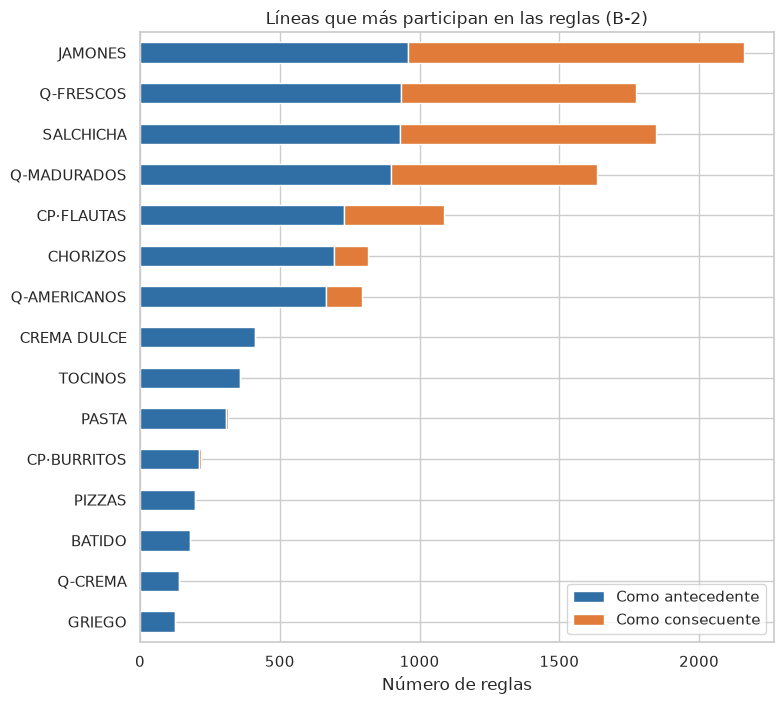

In [31]:
print("B-1 – impacto de las reglas simples con mayor lift (importe de Comidas Preparadas):")
imp_B1 = df_cp.pivot_table(index="Transaccion", columns="Descripcion", values="Importe", aggfunc="sum", fill_value=0)
display(impacto(r_b1_simple, b_B1, imp_B1, 8))

print("B-2 – impacto de las reglas HACIA Comidas Preparadas, antecedente de hasta 2 ítems (importe de todo el ticket):")
display(impacto(hacia2, b_B2, imp_B2, 8))
print("B-2 – impacto de las reglas DESDE Comidas Preparadas, antecedente de hasta 2 ítems:")
display(impacto(desde2, b_B2, imp_B2, 8))

part_B2 = participacion(r_b2, 15, "Líneas que más participan en las reglas (B-2)")

**Lectura del impacto (B).**

- **B-1 (dentro del sector).** El mayor respaldo lo tiene Burrito Barbacoa ↔ Burrito Deshebrada: 197 tickets (7.9% de los tickets con Comidas Preparadas) y \$13,824 (6.1% del importe del sector). Las reglas de lift más alto (por ejemplo Burrito Jamón c/Queso → Burrito Deshebrada c/Chipotle, lift 6.4) cubren apenas 56 tickets (2.3%) y \$4,419 (1.9%). El impacto en dinero es modesto porque Comidas Preparadas pesa 6.1% del importe total (\$228,222).
- **B-2, hacia Comidas Preparadas.** Cada regla toca entre 3.4% y 6.1% de los tickets con comida preparada y entre 4.8% y 7.2% del importe de esos tickets. La más amplia es {Chorizos, Crema dulce} → Flautas: 151 tickets (6.1%) y \$59,589 de importe del ticket, de los cuales \$7,687 son flautas.
- **B-2, desde Comidas Preparadas.** Cada regla toca entre 3.1% y 4.8% de los tickets y entre 4.7% y 7.3% del importe. Aquí el consecuente puede valer bastante más: en {Flautas, Especialidades} → {Jamones, Q-Frescos, Q-Madurados} el consecuente suma \$22,048 de \$57,359 (38% del importe de esos tickets), contra \$3.5 mil a \$7.7 mil en las reglas hacia el sector. Quien ya compra comida preparada parece una buena oportunidad para vender líneas de mayor valor del catálogo.
- La gráfica de participación muestra qué líneas aparecen más como antecedente o como consecuente en las reglas de B-2.

## B.6 Evaluación del modelo: Confidence y Lift

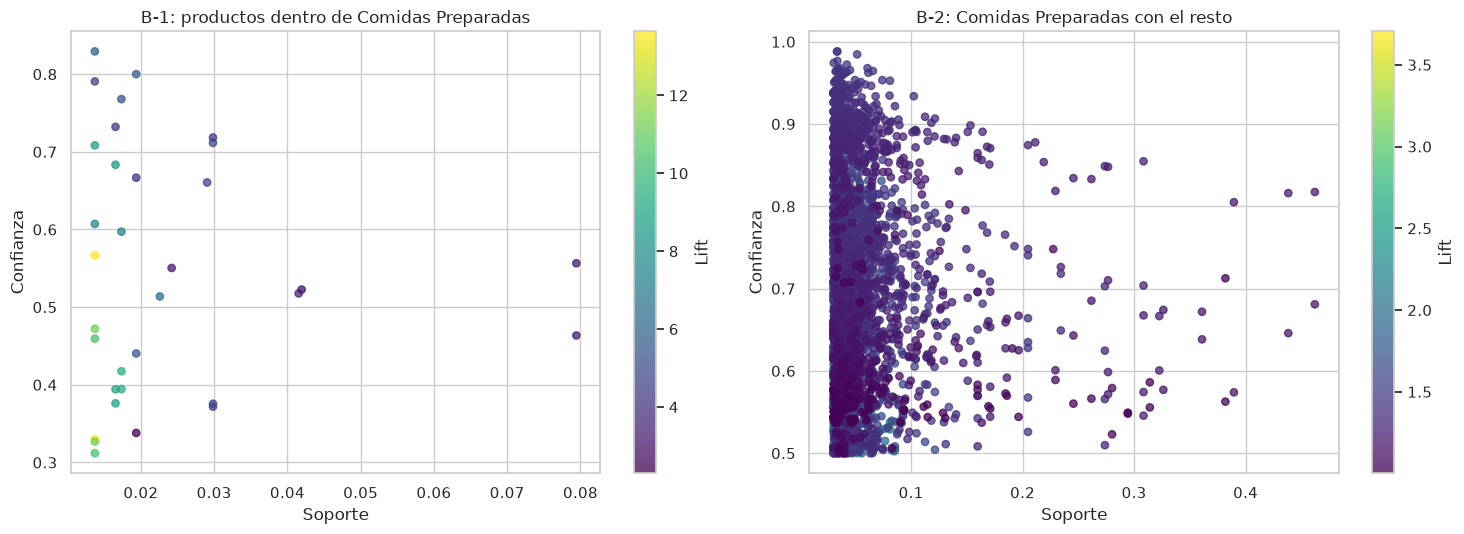

,Conjunto,Reglas,Confianza mediana,Lift mediano,Lift máximo,Reglas con lift ≥ 2,Reglas con lift ≥ 1.5
0,B-1 (dentro de CP),33,0.523,5.605,13.644,33,33
1,B-2 (todas),3149,0.688,1.418,3.705,305,1183
2,B-2 hacia CP,259,0.597,1.120,1.891,0,7
3,B-2 desde CP,976,0.703,1.374,3.261,55,266


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, r, t in [(ax[0], r_b1, "B-1: productos dentro de Comidas Preparadas"), (ax[1], r_b2, "B-2: Comidas Preparadas con el resto")]:
    sc = a.scatter(r["support"], r["confidence"], c=r["lift"], cmap="viridis", s=28, alpha=.75)
    plt.colorbar(sc, ax=a, label="Lift"); a.set_xlabel("Soporte"); a.set_ylabel("Confianza"); a.set_title(t)
plt.tight_layout(); plt.show()

def resumen_ev(r, nombre):
    return {"Conjunto": nombre, "Reglas": len(r), "Confianza mediana": round(r.confidence.median(), 3), "Lift mediano": round(r.lift.median(), 3),
            "Lift máximo": round(r.lift.max(), 3), "Reglas con lift ≥ 2": int((r.lift >= 2).sum()), "Reglas con lift ≥ 1.5": int((r.lift >= 1.5).sum())}
display(pd.DataFrame([resumen_ev(r_b1, "B-1 (dentro de CP)"), resumen_ev(r_b2, "B-2 (todas)"),
                      resumen_ev(hacia, "B-2 hacia CP"), resumen_ev(desde, "B-2 desde CP")]))

In [33]:
# Evaluación por algoritmo: confidence y lift de las reglas de Apriori y de FP-Growth
display(pd.concat([evaluar_algoritmos(out_B1, "B-1"), evaluar_algoritmos(out_B2, "B-2")], ignore_index=True))
for nombre, o in [("B-1", out_B1), ("B-2", out_B2)]:
    ok, dif = diferencia_metricas(o)
    print(f"{nombre}: ¿mismas reglas en ambos algoritmos? {ok} | mayor diferencia en soporte/confianza/lift: {dif:.1e}")

,Conjunto,Algoritmo,Reglas,Confianza media,Confianza mediana,Lift medio,Lift mediano,Lift máximo,Reglas con lift ≥ 1.5,Reglas con lift ≥ 2
0,B-1,Apriori,33,0.545,0.523,6.771,5.605,13.644,33,33
1,B-1,FP-Growth,33,0.545,0.523,6.771,5.605,13.644,33,33
2,B-2,Apriori,3149,0.694,0.688,1.516,1.418,3.705,1183,305
3,B-2,FP-Growth,3149,0.694,0.688,1.516,1.418,3.705,1183,305


B-1: ¿mismas reglas en ambos algoritmos? True | mayor diferencia en soporte/confianza/lift: 0.0e+00
B-2: ¿mismas reglas en ambos algoritmos? True | mayor diferencia en soporte/confianza/lift: 0.0e+00


**Lectura de Confidence y Lift (B).**

- **B-1: lift muy alto, respaldo bajo.** Las 33 reglas tienen lift ≥ 2 (mediana 5.6, máximo 13.6) y confianza mediana de 52.3%; la mayoría son entre variedades de burrito (se compran sabores distintos en el mismo ticket). Pero el soporte mínimo es 1% (≈ 25 tickets), y con tan pocos casos el lift se infla: son hipótesis a probar, no certezas.
- **B-2, hacia Comidas Preparadas: asociaciones débiles.** Confianza mediana de 59.7% pero lift mediano de 1.12 y máximo de 1.89; ninguna de las 259 reglas llega a lift 2 y solo 7 pasan de 1.5. La confianza es alta porque Flautas está en 53.6% de estos tickets (casi cualquier ticket “predice” flautas); para las reglas que terminan en Flautas, el lift no puede pasar de 1.87.
- **B-2, desde Comidas Preparadas: señal moderada.** Lift mediano de 1.37 y máximo de 3.26; 55 de las 976 reglas tienen lift ≥ 2. Entre las de antecedente de hasta 2 productos, las más fuertes giran en torno a {Burritos, Pasta, Q-Americanos} (lift de 2.5 a 2.9).
- **Evaluación por algoritmo:** Apriori y FP-Growth producen las mismas reglas con las mismas métricas (tabla anterior); la evaluación no depende del algoritmo.

## B.7 Comparación de resultados de Apriori y FP-Growth

In [34]:
print("== B-1 =="); cmp_B1 = comparar(out_B1); display(cmp_B1)
print("== B-2 =="); cmp_B2 = comparar(out_B2); display(cmp_B2)
resumen_tiempos.append({"Experimento": "B-1 (Producto, 1%)", "Apriori (s)": out_B1["Apriori"]["t_media"], "FP-Growth (s)": out_B1["FP-Growth"]["t_media"], "Reglas": len(r_b1)})
resumen_tiempos.append({"Experimento": "B-2 (Linea, 3%)", "Apriori (s)": out_B2["Apriori"]["t_media"], "FP-Growth (s)": out_B2["FP-Growth"]["t_media"], "Reglas": len(r_b2)})

== B-1 ==
¿Mismos itemsets con el mismo soporte?: True
¿Mismas reglas?: True


,Algoritmo,Itemsets frecuentes,Itemsets de 2+ ítems,Reglas,Tiempo medio (s),Tiempo mínimo (s)
0,Apriori,44,15,33,0.0060,0.0046
1,FP-Growth,44,15,33,0.0092,0.0085


== B-2 ==
¿Mismos itemsets con el mismo soporte?: True
¿Mismas reglas?: True


,Algoritmo,Itemsets frecuentes,Itemsets de 2+ ítems,Reglas,Tiempo medio (s),Tiempo mínimo (s)
0,Apriori,1020,982,3149,0.0243,0.0239
1,FP-Growth,1020,982,3149,0.1115,0.0729


En B-1 y B-2 ambos algoritmos devuelven exactamente los mismos itemsets y las mismas reglas (las dos verificaciones de arriba dan `True`), así que las conclusiones de B no dependen del algoritmo elegido. Lo único que cambia es el tiempo de ejecución, que se comenta en la celda siguiente con los tiempos medidos.

In [35]:
# Comentario comparativo (B.7): se redacta con los tiempos medidos en esta corrida
ok1, dif1 = diferencia_metricas(out_B1)
ok2, dif2 = diferencia_metricas(out_B2)
display(Markdown(f"""**Comentario de resultados comparativos (Requerimiento B)**

- **B-1 (productos dentro de Comidas Preparadas, soporte {SOP_B1:.0%}):** {len(out_B1["Apriori"]["fi"])} itemsets y {len(out_B1["Apriori"]["reglas"])} reglas en ambos algoritmos (mismas reglas: {ok1}; diferencia máxima en las métricas: {dif1:.1e}). {frase_tiempos(out_B1)}
- **B-2 (Comidas Preparadas con el resto del catálogo, soporte {SOP_B2:.0%}):** {len(out_B2["Apriori"]["fi"])} itemsets y {len(out_B2["Apriori"]["reglas"])} reglas en ambos algoritmos (mismas reglas: {ok2}; diferencia máxima en las métricas: {dif2:.1e}). {frase_tiempos(out_B2)}
- **Lectura:** el algoritmo no cambia lo que se aprende de Comidas Preparadas; solo cambia el tiempo de cómputo, y en estos tamaños (≤ 61 ítems) esa diferencia no condiciona la decisión de negocio."""))

**Comentario de resultados comparativos (Requerimiento B)**

- **B-1 (productos dentro de Comidas Preparadas, soporte 1%):** 44 itemsets y 33 reglas en ambos algoritmos (mismas reglas: True; diferencia máxima en las métricas: 0.0e+00). Apriori 0.006 s y FP-Growth 0.009 s: Apriori fue 1.5 veces más rápido que FP-Growth.
- **B-2 (Comidas Preparadas con el resto del catálogo, soporte 3%):** 1020 itemsets y 3149 reglas en ambos algoritmos (mismas reglas: True; diferencia máxima en las métricas: 0.0e+00). Apriori 0.024 s y FP-Growth 0.111 s: Apriori fue 4.6 veces más rápido que FP-Growth.
- **Lectura:** el algoritmo no cambia lo que se aprende de Comidas Preparadas; solo cambia el tiempo de cómputo, y en estos tamaños (≤ 61 ítems) esa diferencia no condiciona la decisión de negocio.

## B.8 Conclusiones de negocio – Requerimiento B

Comidas Preparadas aparece en 2,480 tickets (21.9%) y pesa 6.1% del importe (\$228,222). Solo 766 de esos tickets (30.9%) llevan 2 o más productos del sector, lo que limita lo que se puede aprender dentro de él.

**B-1. Dentro del sector (soporte 1%, confianza ≥ 30%): 33 reglas, todas con lift ≥ 2 (mediana 5.6)**
- Casi todas las reglas son de la **familia de burritos**: se compran variedades distintas en el mismo ticket. Burrito Barbacoa ↔ Burrito Deshebrada: confianza de 46.4% y 55.6%, lift 3.25, 197 tickets (7.9%) y \$13,824 de importe (6.1% del importe del sector). Burrito Jamón c/Queso → Burrito Deshebrada c/Chipotle: confianza 51.4%, lift 6.4, pero solo 56 tickets.
- En flautas solo aparece una regla: Flautas de Pollo → Flautas de Res (confianza 33.8%, lift 2.3, 48 tickets).
- **Flautas y burritos se sustituyen**: aparecen juntos en 226 tickets (9.1%) con lift 0.56, es decir, se compran juntos menos de lo esperado. No tiene sentido promocionarlos como par.
- Los lifts son altos porque el soporte es bajo (desde 25 tickets); conviene tratarlos como hipótesis a probar.

**B-2. Con el resto del catálogo (soporte 3%, confianza ≥ 50%): 3,149 reglas (259 hacia el sector, 976 desde el sector y ninguna dentro de él)**
- Los tickets con Comidas Preparadas son canastas grandes: 6.6 líneas distintas contra 3.6 en los tickets sin ellas (ticket medio \$332 contra \$328; las medianas se muestran en la celda de verificación de B.1). Son clientes que ya compran mucho; por eso se usa lift y no solo confianza.
- **Hacia Comidas Preparadas las asociaciones son débiles** (lift máximo 1.89, mediana 1.12). Ninguna línea "llama" con fuerza a las comidas preparadas. Las mejores:
  - **{Pasta, Q-Americanos} → Burritos**: confianza 54.6%, lift 1.80, 118 tickets (4.8%), frente a 30.4% de base.
  - **Pechugas Rellenas → Flautas**: confianza 72.7%, lift 1.36. **{Beber, Chorizos} → Flautas**: confianza 77.1%, lift 1.44. Como las flautas están en 53.6% de estos tickets, su lift no puede pasar de 1.87, por lo que estos valores son relativamente altos.
- **Desde Comidas Preparadas, las reglas simples son débiles** (lift de 1.0 a 1.2): quien compra comida preparada lleva también Jamones o Salchicha, pero igual que cualquier cliente. La señal aparece con antecedentes de dos ítems: **{Burritos, Pasta} → Q-Americanos** (confianza 59.6%, lift 2.48, 118 tickets, \$43,525 de importe del ticket) y **{Burritos, Q-Americanos} → Pasta** (confianza 52.7%, lift 2.63). Burritos, Pasta y Q-Americanos forman un trío consistente.
- Flautas + Crema ácida lleva a Q-Madurados + Jamones (confianza 71.5%, lift 1.84), pero la regla directa Flautas → Crema ácida no alcanza el umbral de confianza de 50% (valor exacto en la celda de verificación de B.4), así que no conviene generalizarla.

**Recomendaciones de promoción (B):**
1. **Paquete surtido de burritos** (por ejemplo, 3 sabores: Barbacoa, Deshebrada y Jamón c/Queso), apoyado en una regla de 197 tickets y lift de 3.25.
2. **Combo "Burritos + Pasta + Q-Americanos"**: descuento a quien lleva dos de los tres para que agregue el tercero.
3. **Ofrecer Burritos a quien lleva Pasta y Q-Americanos**, y **Flautas a quien lleva Pechugas Rellenas** (la regla simple con mayor lift hacia flautas, 72.7% de confianza).
4. **No promocionar flautas y burritos juntos**, porque se sustituyen. Si se quiere crecer en uno, la promoción debe ir sola.

**Limitaciones:** Listos para consumo queda fuera de B-2 por su poco volumen (1.8% de los tickets, bajo el soporte de 3%) y Pescados (4.9%, ≈ 122 tickets) entra con poco respaldo; los resultados de B-1 se apoyan en pocos tickets; las reglas son asociaciones, no causas, y deben validarse con un piloto.

---
# Comparación general y conclusiones finales

In [36]:
res = pd.DataFrame(resumen_tiempos)
res["Apriori / FP-Growth"] = (res["Apriori (s)"] / res["FP-Growth (s)"]).round(2)
display(res.round(4))

,Experimento,Apriori (s),FP-Growth (s),Reglas,Apriori / FP-Growth
0,"A (Linea, 3%)",0.0366,0.1086,551,0.34
1,"B-1 (Producto, 1%)",0.0060,0.0092,33,0.65
2,"B-2 (Linea, 3%)",0.0243,0.1115,3149,0.22


## Conclusiones generales

**Sobre los algoritmos.** Apriori y FP-Growth devolvieron **exactamente los mismos itemsets (con el mismo soporte) y las mismas reglas** en los tres experimentos: A (551 reglas), B-1 (33) y B-2 (3,149). La elección entre ellos no cambia ninguna conclusión de negocio; solo cambia el tiempo de ejecución, que se resume en la celda siguiente con los tiempos medidos en esta corrida.

In [37]:
# Resumen comparativo de algoritmos: se redacta con los tiempos medidos en esta corrida
n_exp = len(res)
gana_ap = int((res["Apriori (s)"] < res["FP-Growth (s)"]).sum())
fp_gana = esc[esc["FP-Growth (s)"] < esc["Apriori (s)"]]
if gana_ap == n_exp and fp_gana.empty:
    rec = ("Para estos datos conviene **Apriori**: obtiene los mismos resultados y fue más rápido en todos los experimentos; "
           "la ventaja teórica de FP-Growth no se observó con esta librería y estos volúmenes.")
elif gana_ap == 0 and len(fp_gana) == len(esc):
    rec = ("Para estos datos conviene **FP-Growth**: obtiene los mismos resultados y fue más rápido en todos los experimentos, "
           "con ventaja creciente al bajar el soporte.")
else:
    rec = ("Ninguno domina: " + ("FP-Growth superó a Apriori con soporte de " + ", ".join(f"{s:.1%}" for s in fp_gana["Soporte"]) + " a nivel Producto. "
           if len(fp_gana) else "") + "Conviene elegir según el soporte y el número de ítems con los que se trabaje.")

display(Markdown(f"""**Tiempos medidos en esta corrida (`mlxtend` {mlxtend.__version__}).** En los experimentos A, B-1 y B-2 (tabla de arriba), Apriori fue más rápido en {gana_ap} de {n_exp} y FP-Growth en {n_exp - gana_ap}. En la prueba de escalabilidad a nivel Producto, FP-Growth fue más rápido en {len(fp_gana)} de {len(esc)} soportes. {rec} Los tiempos exactos cambian entre equipos y versiones de la librería; los itemsets y las reglas no."""))

**Tiempos medidos en esta corrida (`mlxtend` 0.25.0).** En los experimentos A, B-1 y B-2 (tabla de arriba), Apriori fue más rápido en 3 de 3 y FP-Growth en 0. En la prueba de escalabilidad a nivel Producto, FP-Growth fue más rápido en 4 de 5 soportes. Ninguno domina: FP-Growth superó a Apriori con soporte de 3.0%, 2.0%, 1.0%, 0.5% a nivel Producto. Conviene elegir según el soporte y el número de ítems con los que se trabaje. Los tiempos exactos cambian entre equipos y versiones de la librería; los itemsets y las reglas no.

**Sobre el negocio.**
1. El catálogo tiene un **núcleo muy comprado** (Jamones, Q-Frescos, Q-Madurados, Salchicha) cuyas reglas tienen alta confianza pero lift bajo: no necesitan descuentos cruzados.
2. Las **promociones con más potencial** salen de asociaciones con lift alto y menor penetración: combos con **Chorizos** (A), **paquete surtido de burritos** y **Burritos + Pasta + Q-Americanos** (B).
3. En Comidas Preparadas, **flautas y burritos se sustituyen**; las promociones deben diseñarse por separado.
4. La mayoría de las asociaciones es moderada (lift mediano de 1.55 en A y de 1.12 hacia Comidas Preparadas en B-2). Antes de invertir, se recomienda un **piloto con grupo de control** para medir el incremento real de cada promoción.

**Limitaciones generales:** los datos son de empleados de empresas corporativas entre 2014 y 2016; no se controló la estacionalidad (las líneas navideñas quedan fuera por su bajo soporte); y las reglas de asociación describen qué se compra junto, no por qué.